In [1]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, '.'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# HARQ x map helper study — results (campaign v3)

Same analysis as `STUDY_RESULTS_v3.ipynb` (Kuo's helper selection), with the helper chosen on the **building map**
(`--helperSelect=map`), and a last section comparing the two selections arm by arm.

**Helper selection.** Kuo's rule (`kuo`) picks the helper from distances only. The map rule (`map`) scores every
member with the building map and the CAM positions: a building on the leader -> member or member -> tail segment
counts as NLOS, another vehicle as NLOSv. It uses exact positions (`posErrM` = 0, CAMs about 30-50 ms old) and a
perfect building map, so it is the best case of a map-based choice. Everything else is identical: every map run has
the same command as the Kuo run of the same cell and seed except `--helperSelect`.

**Data**, campaign v3 (commit 32e29dd, 10 seeds): SCI 1-A on every PSSCH (`--sciOnEveryTx=true`) and the leader's
aperiodic traffic on dynamic grants; every arm at 0, 15, 30, 45 and 60 background vehicles (bg `none`, `n15`,
`n30`, `n45`, `moderate`). The notebook reads `out/study_v3_map/`, symlinks made by `build_study_map_notebook.py`:

| folder | runs | source |
|---|---|---|
| `R1`, `R1_bsc`, `R2`, `R3` | leader only | `out/remote_v3` |
| `R4`, `R4.1`, `R4.2`, `R5`, `R6` | **map** helper | `out/remote_v3_map/<arm>_map` |
| `R4_kuo` ... `R6_kuo` | Kuo helper (comparison section only) | `out/remote_v3/<arm>` |

Arms (all 3 transmissions per TB; S1 = helper relays in slots the leader reserved). In every section before the
last, R4 ... R6 are the **map** arms:

| family | arms |
|---|---|
| leader only | **R1** blind (copies decoded independently), **R2** HARQ Option 1, **R3** HARQ Option 2 |
| map helper, no takeover | **R4** blind (Kuo's scheme with the map helper), **R4.1** HARQ Option 1, **R4.2** HARQ Option 2 |
| map helper + takeover | **R5** Option 1, **R6** Option 2 — helper NACK lets the leader retake the next handed slot (Option 1 via a dedicated helper NACK resource; Option 2 helper silent on success), plus the **leader fallback**: if the leader decodes no SCI of the helper in a handed slot where a relay was expected, it retransmits in the next handed slot |
| blind + soft combining | **R1_bsc**: R1 with the blind copies soft-combined at the receivers (R4_bsc exists for Kuo only) |

Cells: highway / roundabout (N -> W exit, 1/4 of the ring) / roundaboutE (N -> E exit, 3/4 of the ring) (IVD 30 m; roundabout KPIs over the curve only) x periodic1tb / aperiodic1tb x 0-60 background vehicles (1.67 flows each).
Metrics: PRR = delivered / sent per member (mean over members; *worst* = worst member); tx/pkt and reserved/pkt in subchannel-slots per packet
(transmitted PSSCH of the platoon, and leader SCI-1A reservations); platoon CBR = platoon subchannel-slots / available; PSFCH/TB = feedback received by the leader per TB.

In [2]:

import csv, glob, gzip, json, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = os.environ.get('STUDY_OUT', '/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study/out/study_v3_map')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
SLOT = 0.5e-3; NSUB = 5; NMEM = 8
ORDER = ['R1', 'R2', 'R3', 'R4', 'R4.1', 'R4.2', 'R5', 'R6']
LABEL = {'R1': 'R1 leader blind', 'R2': 'R2 leader Opt1', 'R3': 'R3 leader Opt2',
         'R4': 'R4 map blind', 'R4.1': 'R4.1 map+Opt1', 'R4.2': 'R4.2 map+Opt2',
         'R5': 'R5 map+Opt1+takeover', 'R6': 'R6 map+Opt2+takeover'}
KUO = ['R4_kuo', 'R4.1_kuo', 'R4.2_kuo', 'R5_kuo', 'R6_kuo']   # Kuo selection, comparison section only
LABEL.update({k: LABEL[k[:-4]].replace('map', 'Kuo') for k in KUO})
# one distinct hue per arm (8-slot categorical palette, colour-blind checked), line style + marker
# per family as secondary encoding: dotted / circle leader only, dashed / square map helper,
# solid / triangle map helper + takeover
STYLE = {'R1': ('#2a78d6', ':'), 'R2': ('#eb6834', ':'), 'R3': ('#1baf7a', ':'),
         'R4': ('#eda100', '--'), 'R4.1': ('#e87ba4', '--'), 'R4.2': ('#008300', '--'),
         'R5': ('#4a3aa7', '-'), 'R6': ('#e34948', '-')}
MARK = {':': 'o', '--': 's', '-': '^'}

from scipy import stats
def ci95(x):
    """half-width of the 95 % confidence interval of the mean across seeds (Student t, n-1 dof)"""
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

def mean_ci(df, cols, by):
    """per group: <col> = mean over seeds, <col>_ci = 95 % CI half-width"""
    g = df.groupby(by)[cols]
    return g.mean().join(g.agg(ci95).add_suffix('_ci')).reset_index()

def rd(p):
    p = p if os.path.exists(p) else p + '.gz'
    if not os.path.exists(p):
        return None
    return pd.read_csv(p, compression='gzip' if p.endswith('.gz') else None)

def cell_of(tag):
    sc, ivd, tr, bg, s = tag.split('_')
    return dict(scenario={'hwy': 'highway', 'rbt': 'roundabout', 'rbtE': 'roundaboutE'}[sc], traffic=tr, bg=bg, seed=int(s[1:]))

def reserved_subch_slots(gr, k0, k1):
    """Leader reservations announced in SCI-1A over the KPI window [k0, k1) (s): every created grant
    reserves sb_len x slots per period; an SB-SPS grant repeats every RRI until the next creation."""
    if gr is None or len(gr) == 0:
        return np.nan
    c = gr[(gr.node == 0) & (gr.event == 'c')].sort_values('t').reset_index(drop=True)
    tot = 0.0
    for i, g in c.iterrows():
        per = g.sb_len * g.slots_or_counter
        if g.sps == 1 and g.rri_ms > 0:
            t_end = c.t[i + 1] if i + 1 < len(c) else k1
            a, b = max(g.t, k0), min(t_end, k1)
            if b > a:
                tot += per * (b - a) / (g.rri_ms * 1e-3)
        elif k0 <= g.t < k1:
            tot += per
    return tot

# subchannel-slot and PSFCH-resource cost (definitions: paper_v2/analysis/paper_data.py, cost_metrics)
import sys
sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(OUT)), '..', 'paper_v2', 'analysis'))
import paper_data as PD

runs, members, rec = [], [], []
for armdir in sorted(glob.glob(os.path.join(OUT, '*', ''))):
    arm = os.path.basename(armdir.rstrip('/'))
    for p in sorted(glob.glob(armdir + '*_run.csv*')):
        tag = os.path.basename(p).split('_run.csv')[0]
        pre = os.path.join(armdir, tag)
        r = rd(pre + '_run.csv').iloc[0].to_dict()
        c = cell_of(tag)
        k0, k1 = r['kpi_start'], r['kpi_end']
        slots = (k1 - k0) / SLOT
        used = r['res_used_leader'] + r['res_used_helper']
        resv = reserved_subch_slots(rd(pre + '_grants.csv'), k0, k1)
        ntb = max(r['leader_new_tb'], 1)
        row = dict(arm=arm, tag=tag, **c, prr=r['prr_mean'], prr_worst=r['prr_min'], pkts=r['pkts'],
                   tx_per_pkt=used / r['pkts'], resv_per_pkt=resv / r['pkts'],
                   cbr_platoon=used / (slots * NSUB), cbr_total=r['cbr'],
                   psfch_per_tb=(r['nack_rx'] + r['explicit_ack_rx']) / ntb,
                   helper_nack=r['helper_nack'], helper_reclaim=r['helper_reclaim'],
                   fallback_check=r['fallback_check'], fallback_heard=r['fallback_heard'],
                   fallback_tx=r['fallback_tx'], fallback_no_slot=r['fallback_no_slot'])
        m = rd(pre + '_member.csv')
        m = m[m.member != 'all'].copy()
        m['member'] = m.member.astype(int)
        row['prr_pdb'] = m.prr_pdb.mean()
        row['prr_pdb_worst'] = m.prr_pdb.min()
        for _, x in m.iterrows():
            members.append(dict(arm=arm, **c, member=x.member, dist=x.mean_dist_m, prr=x.prr, prr_pdb=x.prr_pdb))
        # member-packets first delivered by a leader retransmission in a handed slot it took back
        ltx, att = rd(pre + '_ltx.csv'), rd(pre + '_att.csv')
        rec1 = rec2 = 0
        if ltx is not None and att is not None and 'origin' in ltx and (ltx.origin > 0).any():
            org = dict(zip(ltx.slot_abs, ltx.origin))
            a = att[(att.t >= k0) & (att.t < k1)].sort_values('t')
            first = a[a.status == 1].groupby(['tb', 'member']).first().reset_index()
            for _, x in first.iterrows():
                if x.side == 0:
                    o = org.get(x.slot_abs, 0)
                    rec1 += o == 1
                    rec2 += o == 2
        row['recovered_nack'] = rec1 / (r['pkts'] * NMEM)
        row['recovered_fallback'] = rec2 / (r['pkts'] * NMEM)
        row.update({k: v for k, v in PD.cost_metrics(pre, arm[:-4] if arm.endswith('_kuo') else arm).items() if k != 'ss_check'})
        runs.append(row)
R = pd.DataFrame(runs); M = pd.DataFrame(members)
CELLS = ['scenario', 'traffic', 'bg']
print(f'{len(R)} runs, seeds per cell: {R.groupby(CELLS + ["arm"]).seed.nunique().min()}-{R.groupby(CELLS + ["arm"]).seed.nunique().max()}')


4200 runs, seeds per cell: 10-10


## PRR versus distance from the leader
One curve per arm, one point per member (x = its mean distance). Dotted: leader only; dashed: map helper without takeover; solid: map helper with takeover.

In [3]:

def dist_plot(arms, title, metric='prr'):
    scen = [s for s in ['highway', 'roundabout', 'roundaboutE'] if s in set(M.scenario)]
    trafs, bgs = ['periodic1tb', 'aperiodic1tb'], ['none', 'moderate']
    fig, axes = plt.subplots(len(scen) * len(trafs), len(bgs), figsize=(12, 3.3 * len(scen) * len(trafs)),
                             sharey=True, squeeze=False)
    for i, (sc, tr) in enumerate([(s, t) for s in scen for t in trafs]):
        for j, bg in enumerate(bgs):
            ax = axes[i, j]
            d = M[(M.scenario == sc) & (M.traffic == tr) & (M.bg == bg)]
            for arm in arms:
                g = mean_ci(d[d.arm == arm], ['dist', metric], 'member').sort_values('dist')
                if len(g):
                    col, ls = STYLE[arm.replace('_noIR', '')]
                    ax.plot(g.dist, g[metric], ls if '_noIR' not in arm else '-.', color=col, lw=1.6,
                            marker=MARK[ls], ms=4, mfc='white' if '_noIR' in arm else col,
                            label=LABEL.get(arm, arm))
                    ax.fill_between(g.dist, g[metric] - g[metric + '_ci'], g[metric] + g[metric + '_ci'],
                                    color=col, alpha=.12, lw=0)
            ax.set_title(f'{sc} / {tr} / bg {bg}', fontsize=9)
            ax.grid(alpha=.3)
            if j == 0: ax.set_ylabel(metric.upper())
            if i == len(scen) * len(trafs) - 1: ax.set_xlabel('mean distance from the leader (m)')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=min(len(h), 4), fontsize=8, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(title + '  (shaded: 95 % CI over seeds)', y=1.03); fig.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()


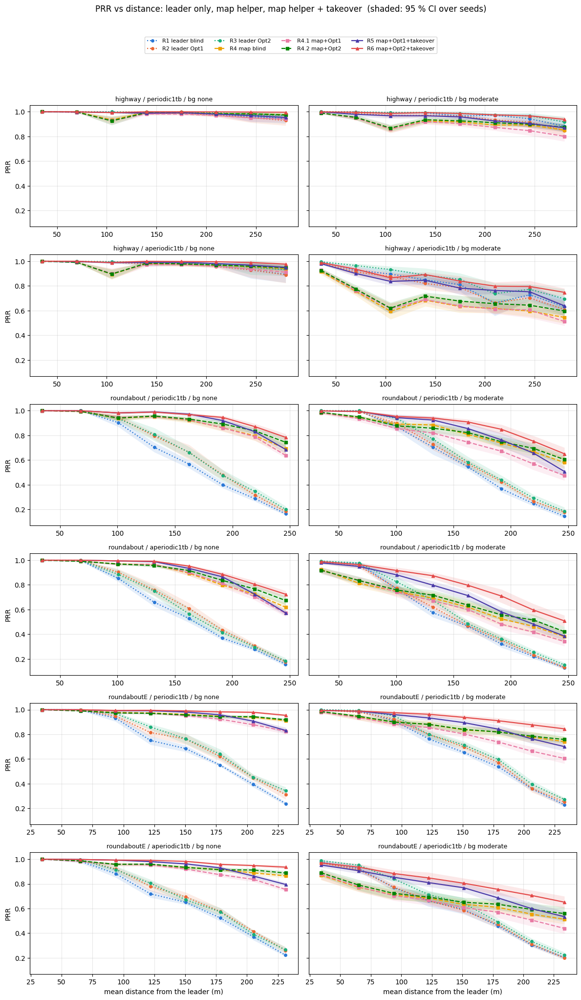

In [4]:
dist_plot(ORDER, 'PRR vs distance: leader only, map helper, map helper + takeover')

*PRR vs distance, HARQ-IR on vs off*: removed. The `_noIR` arms were run only in the pre-fix campaign (deleted); mixing them with v3 data would compare a fixed and an unfixed receiver.

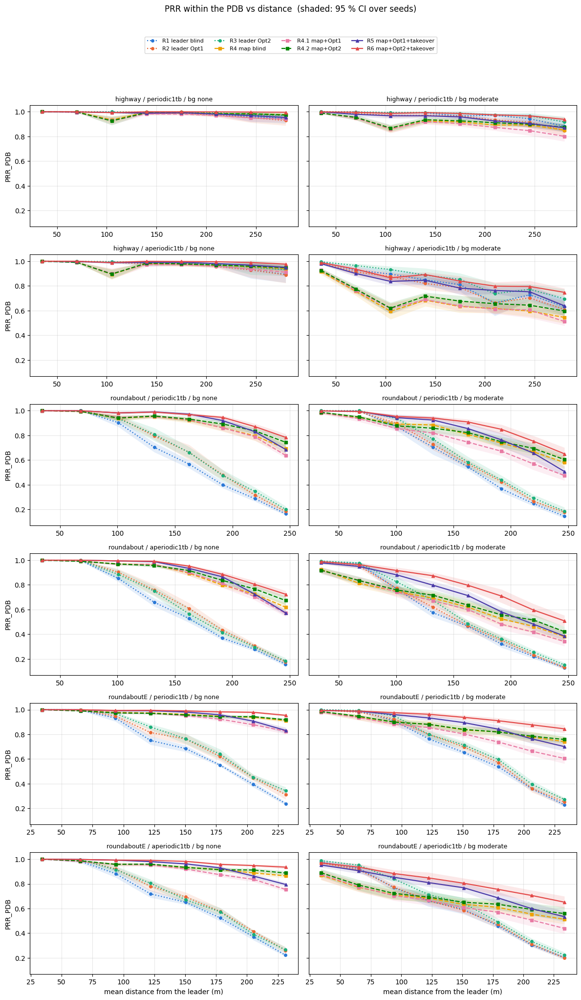

In [5]:
dist_plot(ORDER, 'PRR within the PDB vs distance', metric='prr_pdb')

## PRR versus distance per load level (campaign v3)
Arms R1, R1_bsc, R2, R3 and the map helper arms R4 ... R6, at every load. One point per member: x = its mean distance from the leader over the KPI window
(roundabouts: the curve only), y = its PRR, mean over 10 seeds, shaded = 95 % CI over seeds.
CBR = `cbr_occupied` of the run (distinct (slot, subchannel) cells used by any vehicle / all cells), averaged over
the runs of the (scenario, traffic, load) cell.

* **Figure set A** (one figure per scenario x traffic): one panel per load level, one line per retransmission method.
* **Figure set B** (one figure per scenario x traffic): one panel per method, one line per load (CBR) level.

In [6]:
# v2 per-member PRR (full + density campaigns)
V2_ROOT = os.environ.get('STUDY_V2_ROOT', os.path.dirname(OUT.rstrip('/')))
V2_DIRS = [OUT]   # campaign v3: one folder holds every arm and load (names V2_* kept from the v2 notebook)
NBG_OF = {'none': 0, 'n15': 15, 'n30': 30, 'n45': 45, 'moderate': 60}
SCEN_OF = {'hwy': 'highway', 'rbt': 'roundabout', 'rbtE': 'roundaboutE'}
ARMS_V2 = ['R1', 'R1_bsc', 'R2', 'R3', 'R4', 'R4.1', 'R4.2', 'R5', 'R6']
LABEL_V2 = {'R1': 'R1 leader blind', 'R1_bsc': 'R1_bsc leader blind + comb.', 'R2': 'R2 leader Opt1',
            'R3': 'R3 leader Opt2', 'R4': 'R4 map blind',
            'R4.1': 'R4.1 map+Opt1', 'R4.2': 'R4.2 map+Opt2', 'R5': 'R5 map+Opt1+takeover',
            'R6': 'R6 map+Opt2+takeover (proposed)'}
# same hue as the arm without combining, dash-dot and open marker for the soft-combining variants
STYLE_V2 = dict(STYLE, **{'R1_bsc': ('#2a78d6', '-.')})
mrows, crows = [], []
for d0 in V2_DIRS:
    for p in sorted(glob.glob(os.path.join(d0, '*', '*_member.csv*'))):
        arm = os.path.basename(os.path.dirname(p))
        if arm not in ARMS_V2:
            continue
        tag = os.path.basename(p).split('_member.csv')[0]
        sc, _, tr, bg, s = tag.split('_')
        key = dict(arm=arm, scenario=SCEN_OF[sc], traffic=tr, nbg=NBG_OF[bg], seed=int(s[1:]))
        m = rd(os.path.join(os.path.dirname(p), tag) + '_member.csv')
        m = m[m.member != 'all']
        for _, x in m.iterrows():
            mrows.append(dict(key, member=int(x.member), dist=x.mean_dist_m, prr=x.prr))
        r = rd(os.path.join(os.path.dirname(p), tag) + '_run.csv').iloc[0]
        crows.append(dict(key, cbr=r.cbr_occupied))
MV, CV = pd.DataFrame(mrows), pd.DataFrame(crows)
CBR_V2 = CV.groupby(['scenario', 'traffic', 'nbg']).cbr.mean()
NBGS = sorted(MV.nbg.unique())
print(f'{len(CV)} runs, {len(MV)} (run, member) rows; seeds per (cell, arm): '
      f'{CV.groupby(["scenario", "traffic", "nbg", "arm"]).seed.nunique().min()}-'
      f'{CV.groupby(["scenario", "traffic", "nbg", "arm"]).seed.nunique().max()}')
display(CBR_V2.unstack('nbg').round(3))

2700 runs, 21600 (run, member) rows; seeds per (cell, arm): 10-10


nbg                          0      15     30     45     60
scenario    traffic                                        
highway     aperiodic1tb  0.007  0.242  0.426  0.588  0.702
            periodic1tb   0.004  0.239  0.424  0.587  0.701
roundabout  aperiodic1tb  0.008  0.230  0.422  0.576  0.691
            periodic1tb   0.005  0.227  0.421  0.575  0.690
roundaboutE aperiodic1tb  0.008  0.230  0.423  0.577  0.691
            periodic1tb   0.005  0.228  0.422  0.576  0.690

In [7]:
def _dist_line(ax, d, col, ls, label, mfc=None):
    g = mean_ci(d, ['dist', 'prr'], 'member').sort_values('dist')
    if not len(g):
        return
    ax.plot(g.dist, g.prr, ls, color=col, lw=1.6, marker=MARK.get(ls, 'D'), ms=4,
            mfc=mfc or col, label=label)
    ax.fill_between(g.dist, g.prr - g.prr_ci, g.prr + g.prr_ci, color=col, alpha=.12, lw=0)

def prr_dist_by_method(sc, tr):
    """Set A: one panel per load level, one line per method."""
    d = MV[(MV.scenario == sc) & (MV.traffic == tr)]
    fig, axes = plt.subplots(1, len(NBGS), figsize=(3.4 * len(NBGS), 3.6), sharey=True, squeeze=False)
    for ax, nbg in zip(axes[0], NBGS):
        x = d[d.nbg == nbg]
        for arm in ARMS_V2:
            col, ls = STYLE_V2[arm]
            _dist_line(ax, x[x.arm == arm], col, ls, LABEL_V2[arm], mfc='white' if arm.endswith('_bsc') else None)
        ax.set_title(f'{nbg} vehicles, CBR {CBR_V2[(sc, tr, nbg)]:.2f}', fontsize=9)
        ax.set_xlabel('mean distance from the leader (m)'); ax.grid(alpha=.3)
    axes[0, 0].set_ylabel('PRR')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, 1.03))
    fig.suptitle(f'{sc} / {tr}: PRR vs distance per method (shaded: 95 % CI)', y=1.1)
    fig.tight_layout(); plt.show()

def prr_dist_by_load(sc, tr):
    """Set B: one panel per method, one line per load (CBR) level."""
    d = MV[(MV.scenario == sc) & (MV.traffic == tr)]
    cmap = plt.cm.viridis_r
    cols = {n: cmap(0.12 + 0.8 * i / (len(NBGS) - 1)) for i, n in enumerate(NBGS)}
    fig, axes = plt.subplots(2, 5, figsize=(17, 6.6), sharey=True, sharex=True)
    for ax, arm in zip(axes.flat, ARMS_V2):
        x = d[d.arm == arm]
        for nbg in NBGS:
            _dist_line(ax, x[x.nbg == nbg], cols[nbg], '-',
                       f'{nbg} vehicles (CBR {CBR_V2[(sc, tr, nbg)]:.2f})')
        ax.set_title(LABEL_V2[arm], fontsize=9); ax.grid(alpha=.3)
    for ax in axes[1]: ax.set_xlabel('mean distance from the leader (m)')
    for ax in axes[:, 0]: ax.set_ylabel('PRR')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f'{sc} / {tr}: PRR vs distance per load level', y=1.03)
    fig.tight_layout(); plt.show()

### Set A: methods compared, one panel per load level

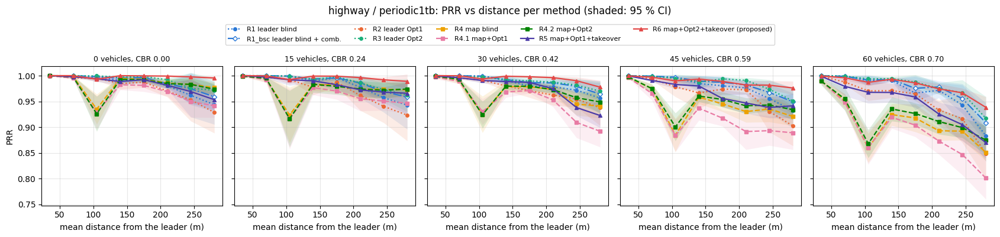

In [8]:
prr_dist_by_method('highway', 'periodic1tb')

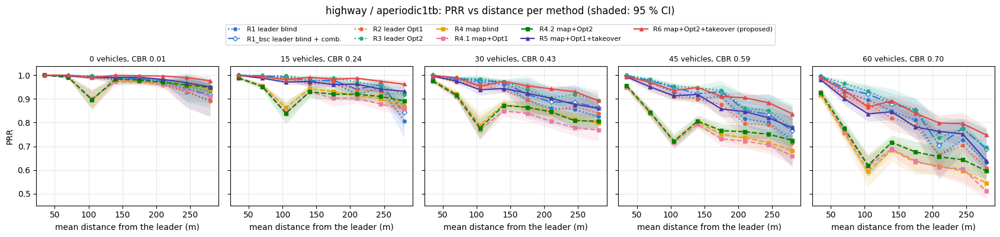

In [9]:
prr_dist_by_method('highway', 'aperiodic1tb')

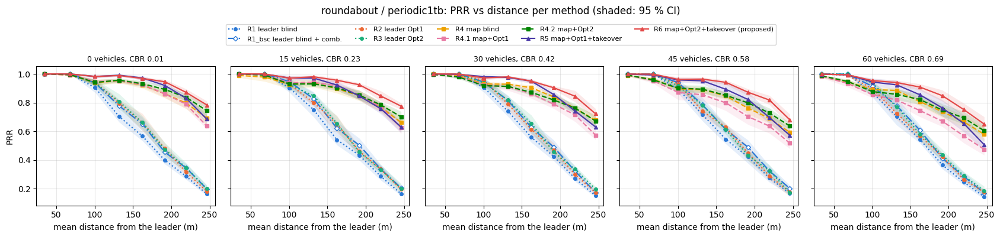

In [10]:
prr_dist_by_method('roundabout', 'periodic1tb')

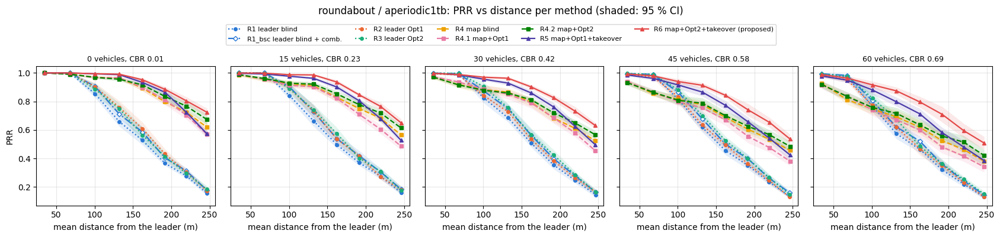

In [11]:
prr_dist_by_method('roundabout', 'aperiodic1tb')

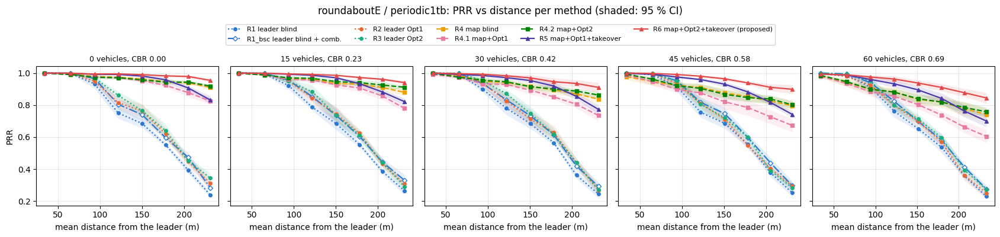

In [12]:
prr_dist_by_method('roundaboutE', 'periodic1tb')

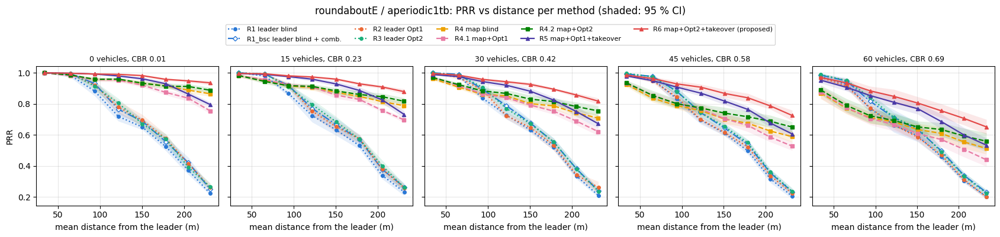

In [13]:
prr_dist_by_method('roundaboutE', 'aperiodic1tb')

### Set B: load levels compared, one panel per method

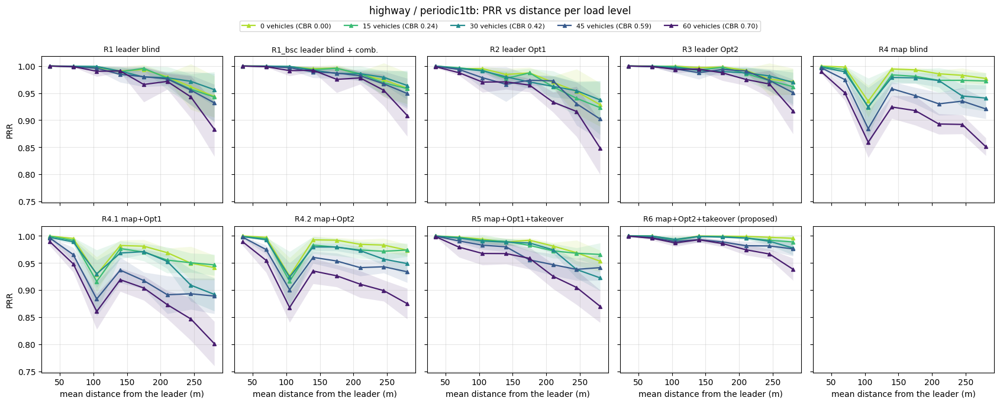

In [14]:
prr_dist_by_load('highway', 'periodic1tb')

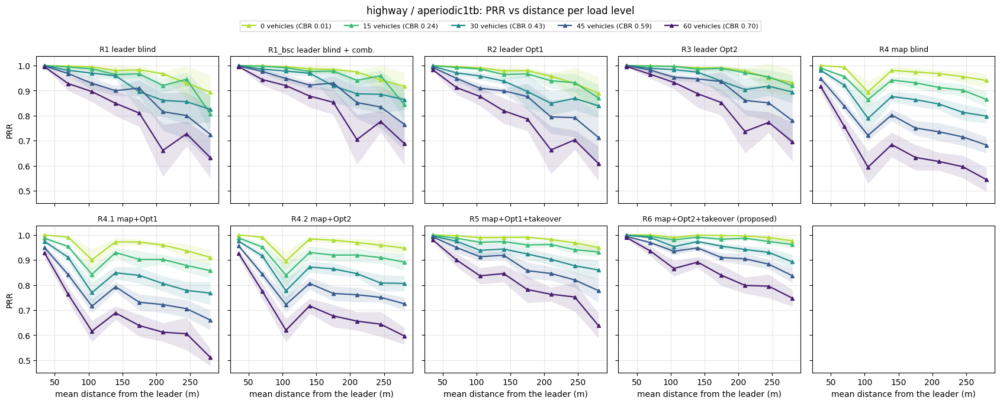

In [15]:
prr_dist_by_load('highway', 'aperiodic1tb')

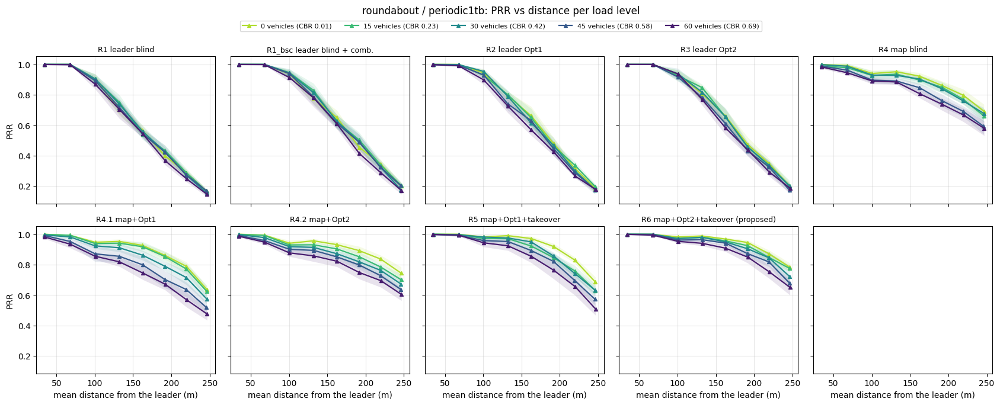

In [16]:
prr_dist_by_load('roundabout', 'periodic1tb')

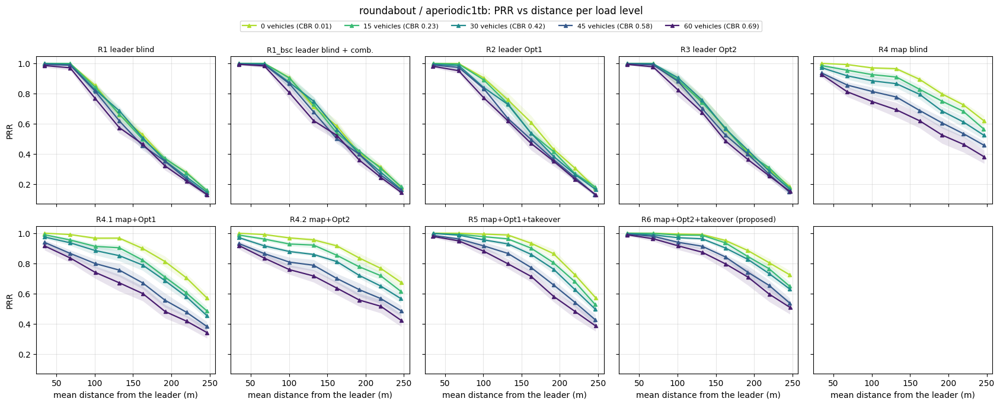

In [17]:
prr_dist_by_load('roundabout', 'aperiodic1tb')

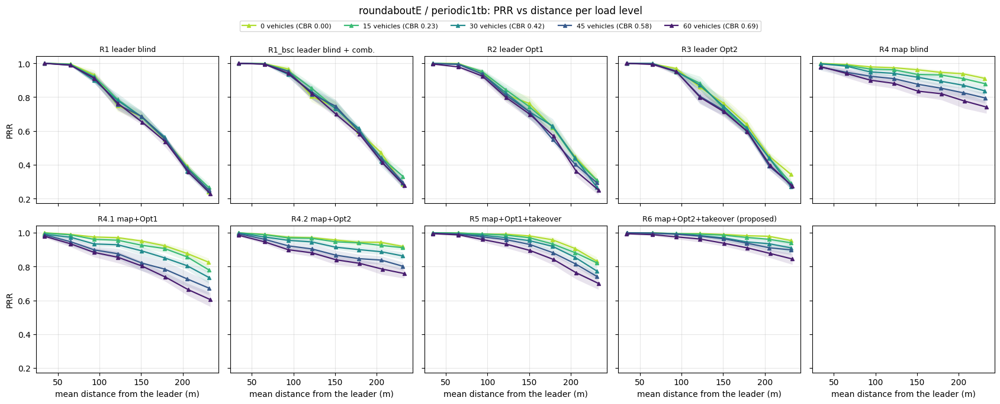

In [18]:
prr_dist_by_load('roundaboutE', 'periodic1tb')

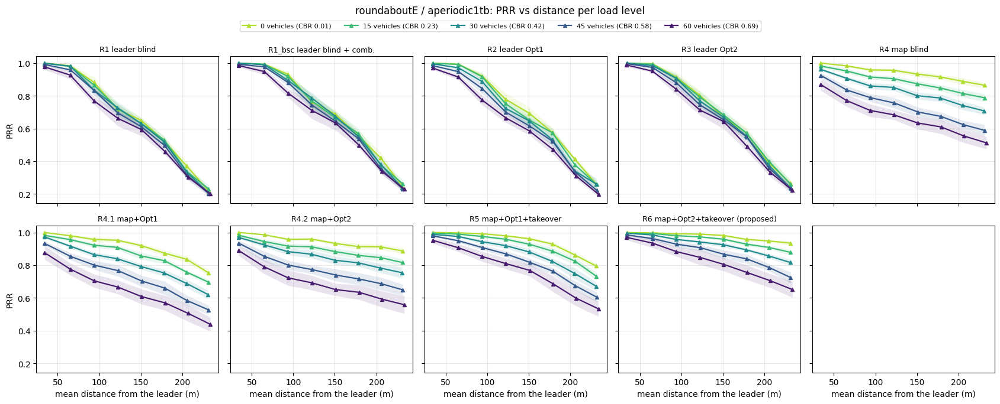

In [19]:
prr_dist_by_load('roundaboutE', 'aperiodic1tb')

## Summary per cell and arm

In [20]:

agg = R.groupby(CELLS + ['arm']).agg(seeds=('seed', 'nunique'), prr=('prr', 'mean'), prr_worst=('prr_worst', 'mean'),
        prr_pdb=('prr_pdb', 'mean'), prr_pdb_worst=('prr_pdb_worst', 'mean'), tx_per_pkt=('tx_per_pkt', 'mean'), resv_per_pkt=('resv_per_pkt', 'mean'),
        cbr_platoon=('cbr_platoon', 'mean'), cbr_total=('cbr_total', 'mean'), psfch_per_tb=('psfch_per_tb', 'mean')).reset_index()
AGGCI = mean_ci(R, ['prr', 'prr_worst', 'prr_pdb', 'prr_pdb_worst', 'cbr_platoon'], CELLS + ['arm'])
main = agg[agg.arm.isin(ORDER)].copy()
main['arm'] = pd.Categorical(main.arm, ORDER)
main.sort_values(CELLS + ['arm']).round(3)


,scenario,traffic,bg,arm,seeds,prr,prr_worst,prr_pdb,prr_pdb_worst,tx_per_pkt,resv_per_pkt,cbr_platoon,cbr_total,psfch_per_tb
0,highway,aperiodic1tb,moderate,R1,10,0.812,0.571,0.812,0.571,9.483,9.486,0.010,0.981,0.000
2,highway,aperiodic1tb,moderate,R2,10,0.794,0.544,0.794,0.544,7.413,9.461,0.008,0.979,3.105
3,highway,aperiodic1tb,moderate,R3,10,0.855,0.624,0.855,0.624,8.642,9.452,0.009,0.981,17.249
4,highway,aperiodic1tb,moderate,R4,10,0.668,0.525,0.668,0.525,6.687,9.551,0.007,0.978,0.000
5,highway,aperiodic1tb,moderate,R4.1,10,0.670,0.509,0.670,0.509,5.146,9.518,0.005,0.977,1.966
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
410,roundaboutE,periodic1tb,none,R4,10,0.963,0.911,0.963,0.911,5.683,5.892,0.006,0.006,0.000
411,roundaboutE,periodic1tb,none,R4.1,10,0.939,0.824,0.939,0.824,3.680,5.892,0.004,0.004,2.226
413,roundaboutE,periodic1tb,none,R4.2,10,0.962,0.917,0.962,0.917,4.092,5.892,0.004,0.004,11.028
416,roundaboutE,periodic1tb,none,R5,10,0.957,0.832,0.957,0.832,3.879,5.892,0.004,0.004,2.252


## Spectrum and CBR savings
Savings against the blind counterpart of the same family (leader arms vs R1, helper arms vs R4): transmitted subchannel-slots (interference / energy), platoon CBR, and reserved (announced) subchannel-slots (capacity for sensing UEs).

In [21]:

ref = {'R1': 'R1', 'R2': 'R1', 'R3': 'R1', 'R4': 'R4', 'R4.1': 'R4', 'R4.2': 'R4', 'R5': 'R4', 'R6': 'R4'}
rows = []
for (sc, tr, bg), g in agg[agg.arm.isin(ORDER)].groupby(CELLS):
    g = g.set_index('arm')
    for arm in ORDER:
        if arm in g.index and ref[arm] in g.index:
            b = g.loc[ref[arm]]
            rows.append(dict(scenario=sc, traffic=tr, bg=bg, arm=arm, vs=ref[arm],
                cbr_platoon=g.loc[arm, 'cbr_platoon'],
                cbr_saving_pct=100 * (1 - g.loc[arm, 'cbr_platoon'] / b.cbr_platoon),
                tx_saving_pct=100 * (1 - g.loc[arm, 'tx_per_pkt'] / b.tx_per_pkt),
                resv_saving_pct=100 * (1 - g.loc[arm, 'resv_per_pkt'] / b.resv_per_pkt),
                d_prr=g.loc[arm, 'prr'] - b.prr, d_prr_worst=g.loc[arm, 'prr_worst'] - b.prr_worst))
CB = pd.DataFrame(rows)
CB.round(3)


,scenario,traffic,bg,arm,vs,cbr_platoon,cbr_saving_pct,tx_saving_pct,resv_saving_pct,d_prr,d_prr_worst
0,highway,aperiodic1tb,moderate,R1,R1,0.010,0.000,0.000,0.000,0.000,0.000
1,highway,aperiodic1tb,moderate,R2,R1,0.008,21.820,21.823,0.271,-0.018,-0.027
2,highway,aperiodic1tb,moderate,R3,R1,0.009,8.868,8.867,0.362,0.042,0.053
3,highway,aperiodic1tb,moderate,R4,R4,0.007,0.000,0.000,0.000,0.000,0.000
4,highway,aperiodic1tb,moderate,R4.1,R4,0.005,22.986,23.050,0.352,0.002,-0.016
...,...,...,...,...,...,...,...,...,...,...,...
235,roundaboutE,periodic1tb,none,R4,R4,0.006,0.000,0.000,0.000,0.000,0.000
236,roundaboutE,periodic1tb,none,R4.1,R4,0.004,35.249,35.249,0.000,-0.024,-0.087
237,roundaboutE,periodic1tb,none,R4.2,R4,0.004,27.994,27.994,0.000,-0.001,0.006
238,roundaboutE,periodic1tb,none,R5,R4,0.004,31.746,31.746,0.000,-0.006,-0.079


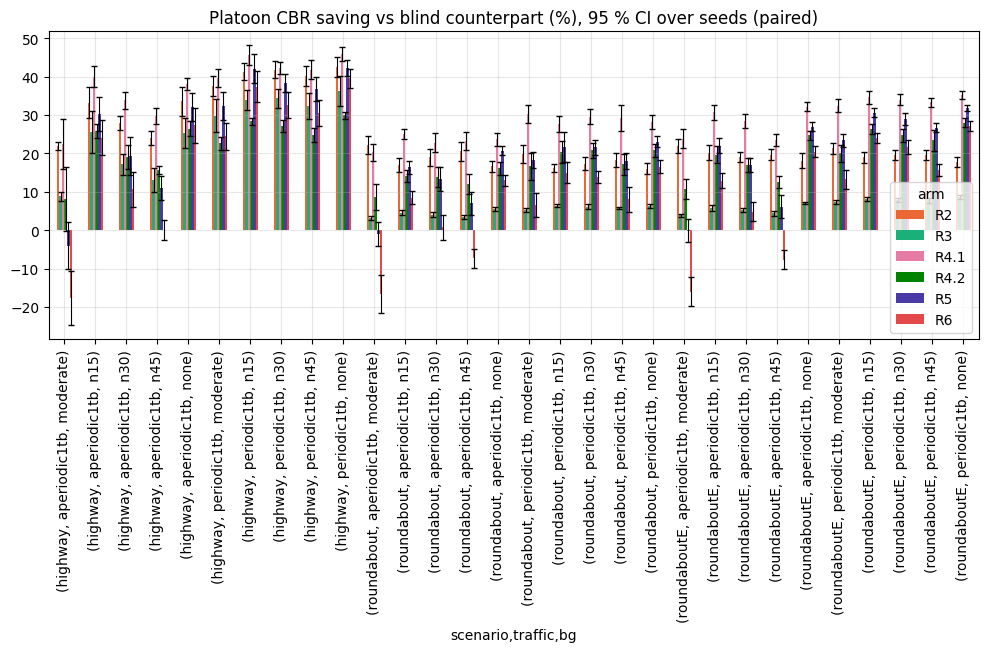

In [22]:
# paired per seed: saving of the arm vs its blind counterpart in the same seed
Rs = R[R.arm.isin(ORDER)].set_index(CELLS + ['seed', 'arm']).cbr_platoon
pr = [dict(scenario=sc, traffic=tr, bg=bg, seed=sd, arm=a, s=100 * (1 - v / Rs.get((sc, tr, bg, sd, ref[a]), np.nan)))
      for (sc, tr, bg, sd, a), v in Rs.items() if a not in ('R1', 'R4')]
pc = mean_ci(pd.DataFrame(pr), ['s'], CELLS + ['arm'])
arms = [a for a in ORDER if a not in ('R1', 'R4')]
p = pc.pivot_table(index=CELLS, columns='arm', values='s')[arms]
e = pc.pivot_table(index=CELLS, columns='arm', values='s_ci')[arms]
p.plot.bar(yerr=e, capsize=2, figsize=(12, 4), color=[STYLE[a][0] for a in arms], error_kw=dict(lw=.8),
           title='Platoon CBR saving vs blind counterpart (%), 95 % CI over seeds (paired)')
plt.grid(alpha=.3); plt.show()

## Cost in 3GPP units: subchannel-slots and PSFCH resources
Subchannel-slot = 10 PRB over the whole slot (AGC, PSCCH, PSSCH, DMRS, PSFCH symbols, guard); a PSSCH on L subchannels costs L. `ss_pkt` transmitted per packet, `ss_kB` per kB of TB payload (packet + 37 B), `ss_resv_kB` reserved in SCI 1-A per kB. PSFCH resource (TS 38.213 sec. 16.3) = 1 PRB x 1 cyclic-shift pair (`sl-NumMuxCS-Pair` per PRB): `psfch_alloc_pkt` tied to the HARQ PSSCHs (Option 1: 1 per PSSCH, + R5 helper; Option 2: 8 per PSSCH), `psfch_tx_pkt` transmitted on (Option 1: PSSCHs with >= 1 NACK; Option 2: every ACK / NACK). Definitions: `paper_v2/analysis/paper_data.py`.

In [23]:
COSTM = ['ss_pkt', 'ss_kB', 'ss_resv_pkt', 'ss_resv_kB', 'psfch_alloc_pkt', 'psfch_tx_pkt']
Ck = mean_ci(R, COSTM, CELLS + ['arm'])
Ck.pivot_table(index=CELLS, columns='arm', values='ss_kB').round(2)

arm                                   R1  R1_bsc     R2     R3     R4   R4.1  R4.1_kuo   R4.2  R4.2_kuo  R4_kuo     R5  R5_kuo     R6  R6_kuo
scenario    traffic      bg                                                                                                                  
highway     aperiodic1tb moderate  12.93   12.93  10.11  11.78   9.03   6.95      6.91   8.23      8.26    9.05   9.34    9.32  10.57   10.56
                         n15       12.89   12.89   8.61   9.59  11.59   6.95      6.97   8.59      8.63   11.51   8.06    8.03   8.78    8.80
                         n30       12.87   12.87   9.28  10.66  10.89   7.19      7.15   8.79      8.80   10.77   8.73    8.67   9.70    9.73
                         n45       12.87   12.87   9.79  11.19  10.23   7.18      7.22   8.63      8.70   10.07   9.09    9.12  10.21   10.09
                         none      12.90   12.90   8.57   9.64  11.87   7.35      7.35   8.72      8.76   11.89   8.03    8.01   8.60    8.63
            periodic1tb  moderate  23.68   23.68  14.77  16.62  21.47  12.96     13.22  16.61     16.63   21.54  14.50   14.20  16.21   15.97
                         n15       23.71   23.71  13.93  15.69  22.52  12.22     12.23  16.13     16.10   22.42  12.98   12.95  14.05   14.07
                         n30       23.77   23.77  13.83  15.61  22.48  12.98     13.00  16.39     16.39   22.43  13.86   13.78  15.13   15.11
                         n45       23.77   23.77  14.23  16.10  21.85  12.71     12.89  16.42     16.60   21.53  13.80   13.66  15.19   15.65
                         none      23.75   23.75  13.67  15.12  22.66  12.25     12.23  15.89     15.88   22.55  13.06   12.86  13.70   13.86
roundabout  aperiodic1tb moderate  12.84   12.84  10.00  12.44   9.61   7.66      7.53   8.77      9.42    9.95   9.70    9.64  11.18   11.57
                         n15       12.88   12.88  10.70  12.29  11.76   8.80      8.60  10.08     10.21   11.05   9.83   10.22  10.75   11.62
                         n30       12.89   12.89  10.44  12.37  11.11   8.57      8.30   9.55     10.04   10.69   9.62   10.07  11.01   11.58
                         n45       12.91   12.91  10.25  12.47  10.45   8.02      7.93   9.17      9.82   10.21   9.70    9.94  11.20   11.67
                         none      12.88   12.88  10.74  12.17  12.13   9.26      8.84  10.18     10.37   11.40   9.62   10.35  10.55   11.61
            periodic1tb  moderate  23.76   23.76  19.04  22.51  20.82  14.52     16.68  17.35     19.84   21.92  17.00   17.84  19.43   21.00
                         n15       23.66   23.66  19.81  22.15  21.99  15.91     17.43  17.48     20.33   22.75  17.19   18.46  18.67   20.68
                         n30       23.64   23.64  19.54  22.21  21.89  15.42     17.11  17.33     20.43   22.51  17.15   18.54  18.85   20.73
                         n45       23.78   23.78  19.43  22.39  20.92  14.78     16.71  17.32     20.19   22.03  17.14   18.22  19.21   20.90
                         none      23.75   23.75  19.94  22.26  22.15  15.90     17.86  17.53     20.27   22.81  17.04   18.80  18.47   20.63
roundaboutE aperiodic1tb moderate  12.84   12.84  10.04  12.35   9.40   7.15      7.63   8.38      9.24    9.99   9.39    9.60  10.88   11.46
                         n15       12.91   12.91  10.30  12.16  11.55   8.00      8.45   9.27     10.17   11.42   8.99    9.70  10.05   11.13
                         n30       12.89   12.89  10.45  12.22  11.04   7.89      8.35   9.15     10.00   11.40   9.16    9.64  10.51   11.16
                         n45       12.90   12.90  10.37  12.34  10.03   7.67      8.21   8.76      9.74   10.70   9.40    9.85  10.79   11.41
                         none      12.88   12.88  10.55  11.97  12.14   8.23      8.72   9.13     10.13   11.97   8.86    9.76   9.65   10.85
            periodic1tb  moderate  23.75   23.75  18.69  22.00  21.07  14.21     15.89  16.82     19.22   22.09  16.13   17.17  18.27   19.92
                        

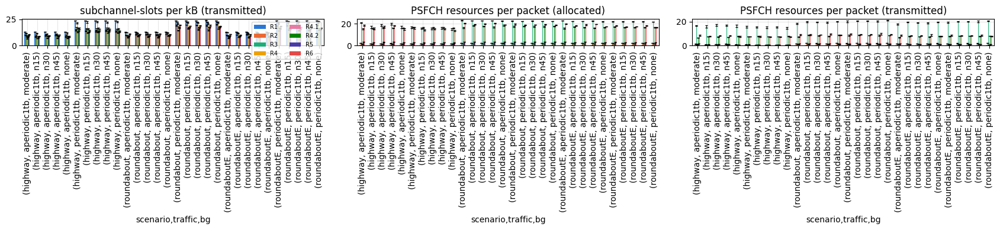

ss_pkt  ss_kB  ss_resv_pkt  ss_resv_kB  psfch_alloc_pkt  psfch_tx_pkt
scenario    traffic      bg       arm                                                                          
highway     aperiodic1tb moderate R1        9.48  12.93         9.49       12.93             0.00          0.00
                                  R1_bsc    9.48  12.93         9.49       12.93             0.00          0.00
                                  R2        7.41  10.11         9.46       12.90             2.24          1.49
                                  R3        8.64  11.78         9.45       12.89            20.97         16.83
                                  R4        6.69   9.03         9.55       12.90             0.00          0.00
...                                          ...    ...          ...         ...              ...           ...
roundaboutE periodic1tb  none     R4_kuo    5.69  22.84         5.89       23.67             0.00          0.00
                                  R5        3.88  15.58         5.89       23.67             3.04          1.08
                                  R5_kuo    4.36  17.51         5.89       23.67             3.27          1.52
                                  R6        4.14  16.64         5.89       23.67            16.86          7.94
                                  R6_kuo    4.76  19.12         5.89       23.67            19.37          9.00

[420 rows x 6 columns]

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (m, lab) in zip(axes, [('ss_kB', 'subchannel-slots per kB (transmitted)'),
                               ('psfch_alloc_pkt', 'PSFCH resources per packet (allocated)'),
                               ('psfch_tx_pkt', 'PSFCH resources per packet (transmitted)')]):
    arms = [a for a in ORDER if a in set(Ck.arm)]
    p = Ck.pivot_table(index=CELLS, columns='arm', values=m).reindex(columns=arms)
    e = Ck.pivot_table(index=CELLS, columns='arm', values=m + '_ci', dropna=False).reindex(columns=arms).fillna(0)
    p.plot.bar(ax=ax, yerr=e, capsize=1.5, color=[STYLE[a][0] for a in arms], error_kw=dict(lw=.6), legend=False)
    ax.set_title(lab); ax.grid(alpha=.3)
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()
Ck.set_index(CELLS + ['arm'])[COSTM].round(2)

## Spectrum use by component
Each bar is the total spectrum one retransmission method uses per generated packet in one scenario, stacked by what occupies it.
Unit: PRB x symbols (PSSCH+PSCCH of a transmission = its PRBs x 9 symbols; one PSFCH resource = 1 PRB x 2 symbols).
Feedback: Option 1 counts one shared NACK resource per transmission with >= 1 member NACK (the R5 helper NACKs on a dedicated
resource); Option 2 counts one resource per ACK / NACK (re-ACKs included; Option-2 ACKs are whole-run counts scaled to the KPI window).
In R4.1 / R4.2 the helper is a plain member, so its feedback is in *members feedback*.

In [25]:

# Spectrum use per generated packet, split by what occupies it (PRB x symbols, KPI window).
# PSSCH (+PSCCH) of a transmission: rb_len PRBs x 9 symbols (every slot carries PSFCH: psfchPeriod 1).
# PSFCH: 1 PRB x 2 symbols per resource. Option 1: one shared NACK resource per transmission that drew
# >= 1 member NACK (the R5 helper NACKs on its own resource); Option 2: one resource per ACK / NACK.
PSSCH_SYM, PSFCH_RE = 9, 2
OPT = {'R1': 0, 'R2': 1, 'R3': 2, 'R4': 0, 'R4.1': 1, 'R4.2': 2, 'R5': 1, 'R6': 2}
COMP = ['leader initial', 'leader retx', 'leader takeover (helper NACK)', 'leader takeover (fallback)',
        'helper relay', 'helper feedback (NACK)', 'members feedback']
CCOL = ['#4c72b0', '#8fa9d6', '#dd8452', '#c44e52', '#55a868', '#937860', '#8172b3']

def helper_at(hs, harq, t):
    if hs is None:
        return None
    h = hs[(hs.harq_id == harq) & (hs.t_ndi <= t + 1e-9)]
    return int(h.applied.iloc[-1]) if len(h) else None

comp_rows = []
for armdir in sorted(glob.glob(os.path.join(OUT, '*', ''))):
    arm = os.path.basename(armdir.rstrip('/'))
    if arm not in OPT:
        continue
    for p in sorted(glob.glob(armdir + '*_run.csv*')):
        tag = os.path.basename(p).split('_run.csv')[0]
        pre = os.path.join(armdir, tag)
        r = rd(pre + '_run.csv').iloc[0]
        k0, k1 = r.kpi_start, r.kpi_end
        win = lambda df: df[(df.t >= k0) & (df.t < k1)] if df is not None and len(df) else df
        ltx, htx = win(rd(pre + '_ltx.csv')), win(rd(pre + '_htx.csv'))
        nack, hs = win(rd(pre + '_nack.csv')), rd(pre + '_hsel.csv')
        c = dict.fromkeys(COMP, 0.0)
        if ltx is not None and len(ltx):
            re_ = ltx.rb_len * PSSCH_SYM
            org = ltx.origin if 'origin' in ltx else 0 * ltx.ndi
            c['leader initial'] = re_[ltx.ndi == 1].sum()
            c['leader retx'] = re_[(ltx.ndi == 0) & (org == 0)].sum()
            c['leader takeover (helper NACK)'] = re_[org == 1].sum()
            c['leader takeover (fallback)'] = re_[org == 2].sum()
        if htx is not None and len(htx):
            c['helper relay'] = (htx.rb_len * PSSCH_SYM).sum()
        takeover = arm in ('R5', 'R6')
        n_help = n_mem = 0
        occ = set()
        if nack is not None and len(nack):
            for x in nack.itertuples():
                h = helper_at(hs, x.harq_id, x.t) if takeover else None
                if takeover and x.member == h:
                    n_help += 1
                else:
                    n_mem += 1
                    occ.add((x.tx_rnti, x.harq_id, round(x.t / SLOT)))
        if OPT[arm] == 1:
            c['members feedback'] = PSFCH_RE * len(occ)
        elif OPT[arm] == 2:
            # ACKs are only counted for the whole run: scale to the KPI window by the share of TBs
            all_ltx = rd(pre + '_ltx.csv')
            frac = (ltx.ndi == 1).sum() / max((all_ltx.ndi == 1).sum(), 1)
            c['members feedback'] = PSFCH_RE * (n_mem + r.explicit_ack_rx * frac)
        c['helper feedback (NACK)'] = PSFCH_RE * n_help
        cc = cell_of(tag)
        comp_rows.append(dict(arm=arm, **cc, **{k: v / r.pkts for k, v in c.items()}))
SP = pd.DataFrame(comp_rows).groupby(CELLS + ['arm'])[COMP].mean().reset_index()
SPT = mean_ci(pd.DataFrame(comp_rows).assign(total=lambda x: x[COMP].sum(axis=1)), ['total'], CELLS + ['arm'])

SUBCH_SLOT = 10 * PSSCH_SYM  # one subchannel (10 PRB) over the PSSCH symbols of a slot

def spectrum_plot(cols, title, ylabel, scale=1.0, prr=False):
    prr_handles = ([], [])
    cells = SP[CELLS].drop_duplicates().sort_values(CELLS).values.tolist()
    nr = -(-len(cells) // 4)   # one row per scenario (4 cells: traffic x bg)
    fig, axes = plt.subplots(nr, 4, figsize=(17, 4.25 * nr), sharey=False, squeeze=False)
    for ax, (sc, tr, bg) in zip(axes.flat, cells):
        d = SP[(SP.scenario == sc) & (SP.traffic == tr) & (SP.bg == bg)].set_index('arm').reindex(
            [a for a in ORDER if a in set(SP.arm)])
        d = d[COMP] / scale
        bottom = np.zeros(len(d))
        for comp, col in zip(COMP, CCOL):
            if comp in cols:
                ax.bar(d.index, d[comp].fillna(0), bottom=bottom, color=col, label=comp, edgecolor='white', lw=.5)
                bottom += d[comp].fillna(0).values
        if set(cols) == set(COMP):   # 95 % CI of the stacked total (all components)
            e = SPT[(SPT.scenario == sc) & (SPT.traffic == tr) & (SPT.bg == bg)].set_index('arm').reindex(d.index)
            ax.errorbar(np.arange(len(d)), bottom, yerr=e.total_ci.values / scale, fmt='none', ecolor='k',
                        elinewidth=.8, capsize=2)
        for i, tot in enumerate(bottom):
            ax.text(i, tot, f'{tot:.0f}' if tot >= 100 else (f'{tot:.1f}' if tot >= 1 else f'{tot:.3f}'),
                    ha='center', va='bottom', fontsize=7)
        if prr:
            q = agg[(agg.scenario == sc) & (agg.traffic == tr) & (agg.bg == bg)].set_index('arm').reindex(d.index)
            ax2 = ax.twinx()
            x = np.arange(len(d))
            pm, pw, tag = (q.prr_pdb, q.prr_pdb_worst, 'PRR within PDB') if prr == 'pdb' else (q.prr, q.prr_worst, 'PRR')
            qc = AGGCI[(AGGCI.scenario == sc) & (AGGCI.traffic == tr) & (AGGCI.bg == bg)].set_index('arm').reindex(d.index)
            em, ew = (qc.prr_pdb_ci, qc.prr_pdb_worst_ci) if prr == 'pdb' else (qc.prr_ci, qc.prr_worst_ci)
            ax2.errorbar(x, pm, yerr=em, fmt='k-o', ms=4, lw=1.2, capsize=2, elinewidth=.8, label=f'{tag} group (mean)')
            ax2.errorbar(x, pw, yerr=ew, fmt='k--^', ms=4, lw=1.2, mfc='white', capsize=2, elinewidth=.8,
                         label=f'{tag} worst member')
            ax2.set_ylim(0, 1.05)
            ax2.tick_params(labelsize=8)
            if (sc, tr, bg) == tuple(cells[-1]) or ax in axes[:, -1]:
                ax2.set_ylabel('PRR')
            prr_handles = ax2.get_legend_handles_labels()
        ax.set_title(f'{sc} / {tr} / bg {bg}', fontsize=9)
        ax.tick_params(axis='x', rotation=45, labelsize=8)
        ax.grid(axis='y', alpha=.3)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    h, l = axes.flat[0].get_legend_handles_labels()
    h, l = h + prr_handles[0], l + prr_handles[1]
    fig.legend(h, l, loc='upper center', ncol=min(len(h), 9), fontsize=8, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(title, y=1.06); fig.tight_layout(); plt.show()


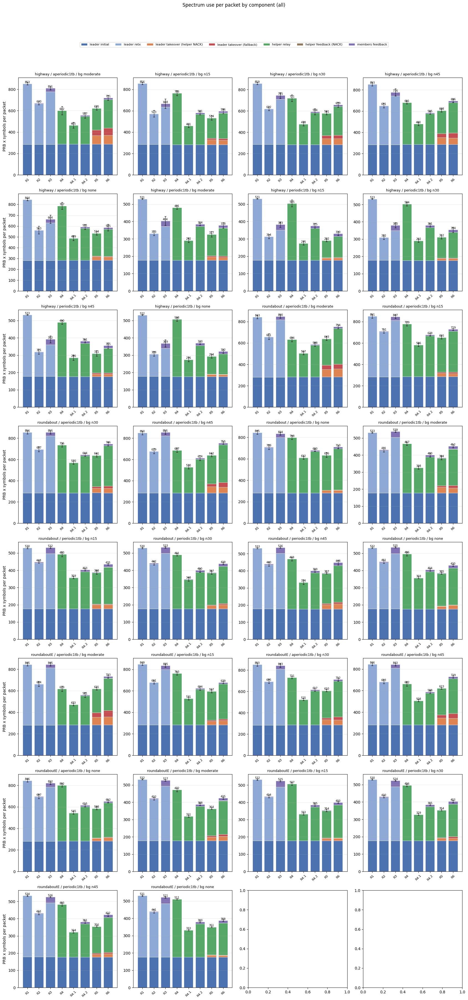

In [26]:
spectrum_plot(COMP, 'Spectrum use per packet by component (all)', 'PRB x symbols per packet')

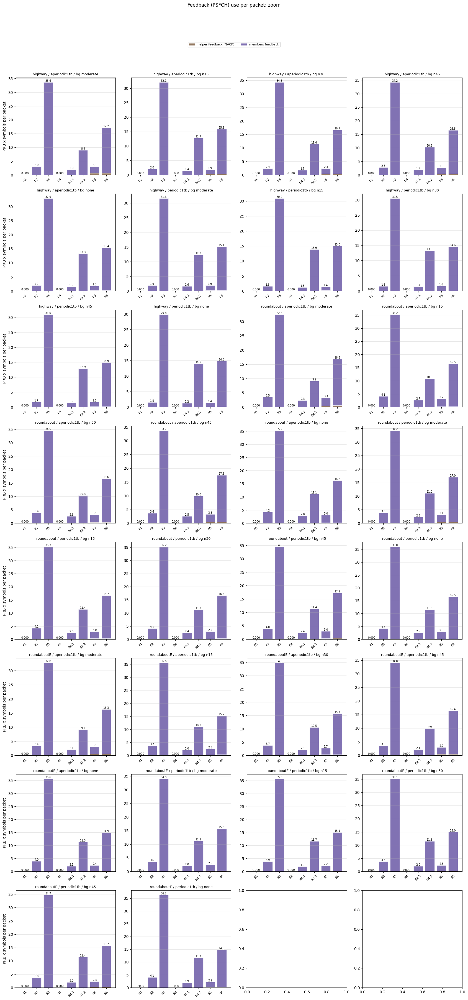

In [27]:
spectrum_plot(['helper feedback (NACK)', 'members feedback'], 'Feedback (PSFCH) use per packet: zoom', 'PRB x symbols per packet')

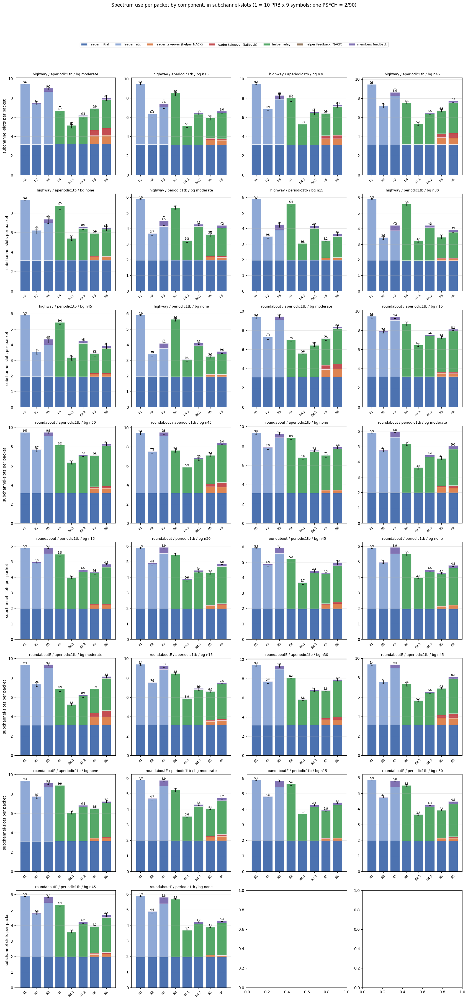

In [28]:
spectrum_plot(COMP, 'Spectrum use per packet by component, in subchannel-slots (1 = 10 PRB x 9 symbols; one PSFCH = 2/90)', 'subchannel-slots per packet', scale=SUBCH_SLOT)

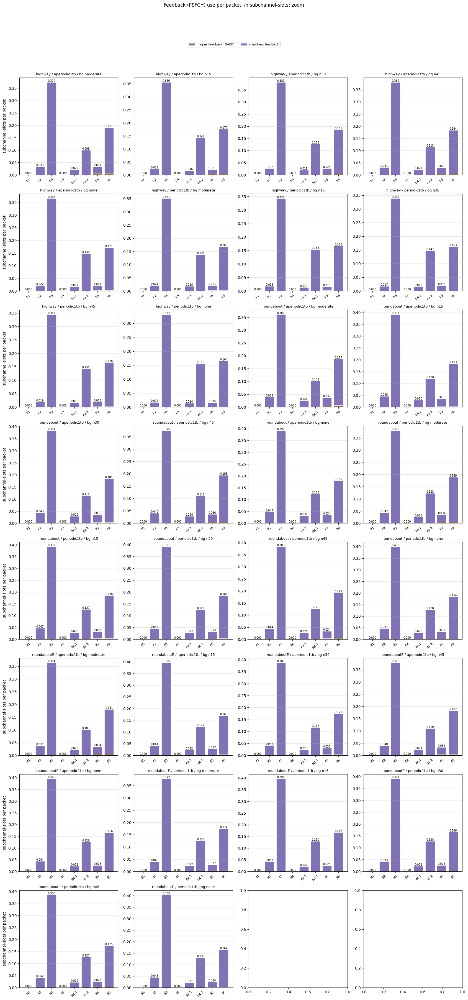

In [29]:
spectrum_plot(['helper feedback (NACK)', 'members feedback'], 'Feedback (PSFCH) use per packet, in subchannel-slots: zoom', 'subchannel-slots per packet', scale=SUBCH_SLOT)

### Spectrum and PRR together (script `plot_spectrum_prr.py`)
Rendered by the standalone script, which also saves `figures/spectrum_prr_{prb,subch}_<profile>.png`.

4200 runs, seeds per cell: 10-10


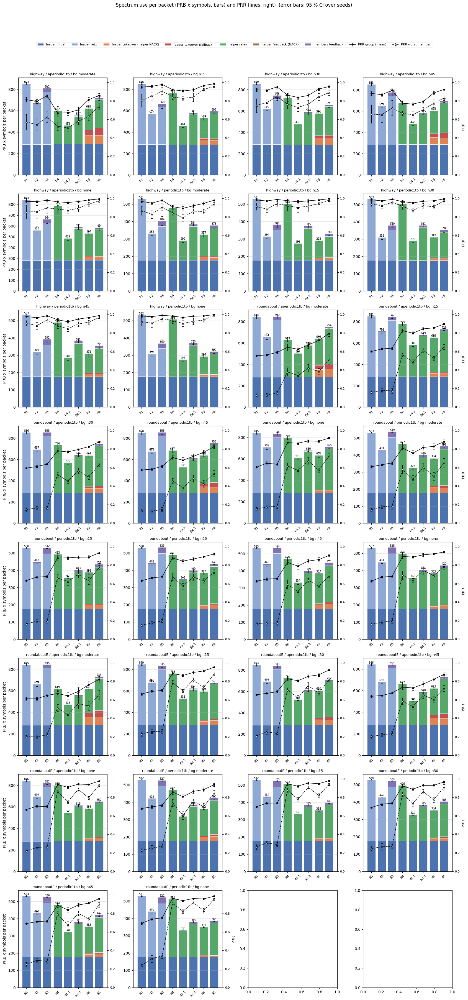

/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study/figures/spectrum_prr_prb_study_v3_map.png


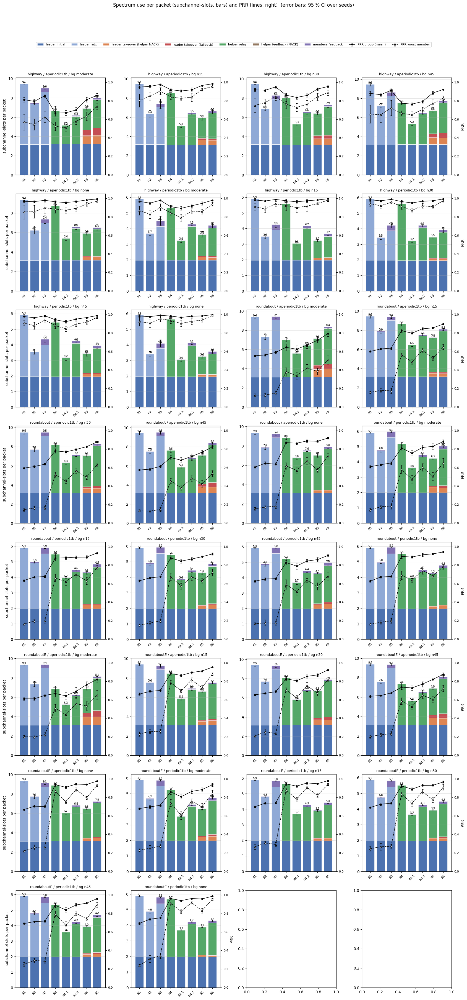

/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study/figures/spectrum_prr_subch_study_v3_map.png


In [30]:
%run scripts/plot_spectrum_prr.py --profile study_v3_map --out {OUT} --show

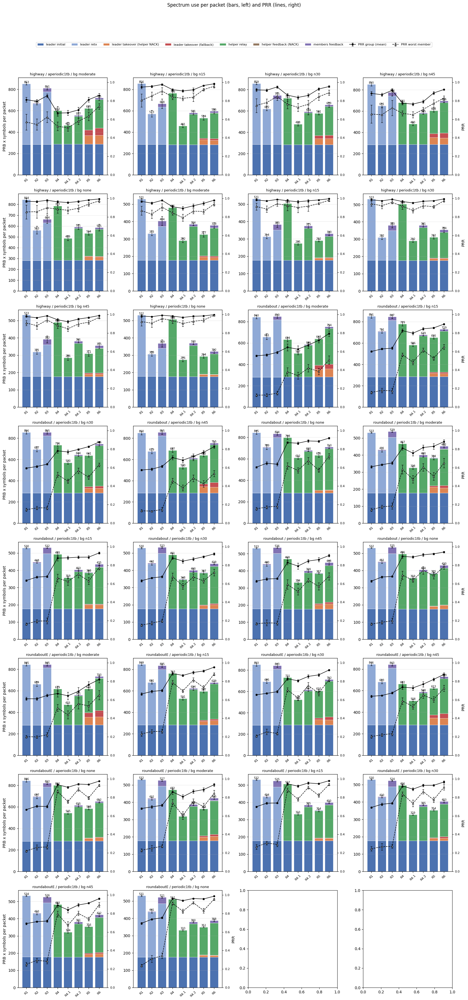

In [31]:
spectrum_plot(COMP, 'Spectrum use per packet (bars, left) and PRR (lines, right)', 'PRB x symbols per packet', prr=True)

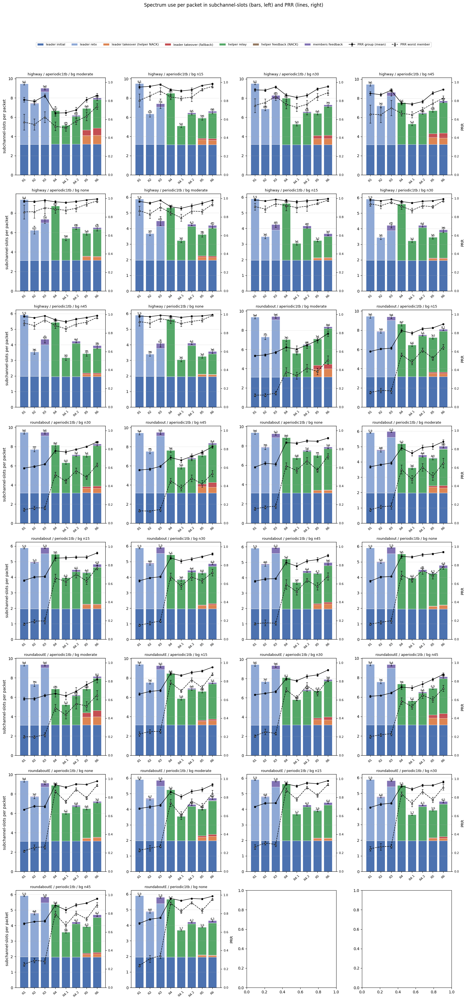

In [32]:
spectrum_plot(COMP, 'Spectrum use per packet in subchannel-slots (bars, left) and PRR (lines, right)', 'subchannel-slots per packet', scale=SUBCH_SLOT, prr=True)

Same two figures with **PRR within the PDB** (packets delivered after the PDB count as lost).

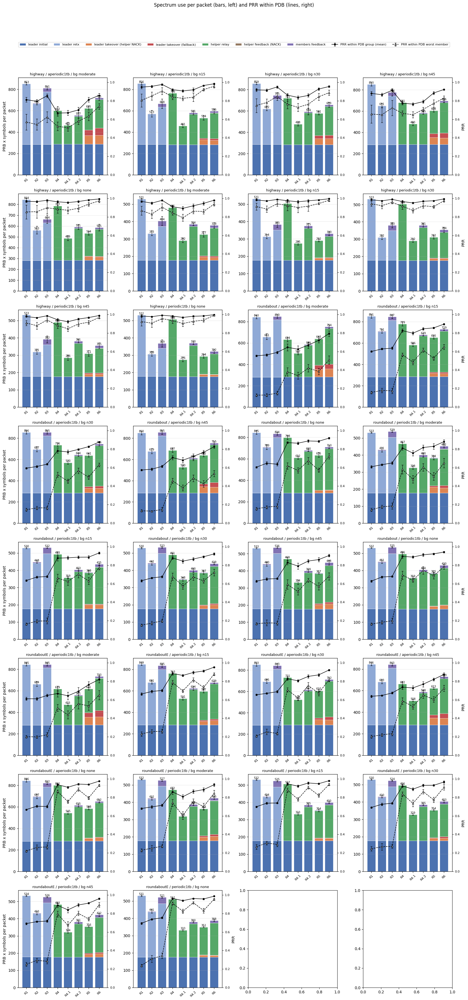

In [33]:
spectrum_plot(COMP, 'Spectrum use per packet (bars, left) and PRR within PDB (lines, right)', 'PRB x symbols per packet', prr='pdb')

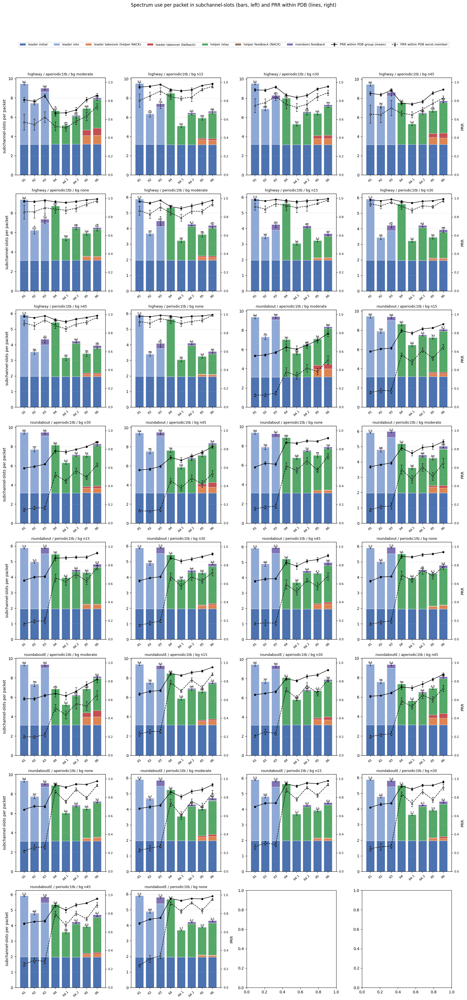

In [34]:
spectrum_plot(COMP, 'Spectrum use per packet in subchannel-slots (bars, left) and PRR within PDB (lines, right)', 'subchannel-slots per packet', scale=SUBCH_SLOT, prr='pdb')

In [35]:
SP.assign(total=SP[COMP].sum(axis=1)).round(1)

,scenario,traffic,bg,arm,leader initial,leader retx,leader takeover (helper NACK),leader takeover (fallback),helper relay,helper feedback (NACK),members feedback,total
0,highway,aperiodic1tb,moderate,R1,284.5,568.9,0.0,0.0,0.0,0.0,0.0,853.5
1,highway,aperiodic1tb,moderate,R2,284.5,382.7,0.0,0.0,0.0,0.0,3.0,670.2
2,highway,aperiodic1tb,moderate,R3,284.5,493.3,0.0,0.0,0.0,0.0,33.6,811.4
3,highway,aperiodic1tb,moderate,R4,286.5,0.0,0.0,0.0,315.3,0.0,0.0,601.8
4,highway,aperiodic1tb,moderate,R4.1,286.5,0.0,0.0,0.0,176.6,0.0,2.0,465.1
...,...,...,...,...,...,...,...,...,...,...,...,...
235,roundaboutE,periodic1tb,none,R4,176.8,0.0,0.0,0.0,334.7,0.0,0.0,511.5
236,roundaboutE,periodic1tb,none,R4.1,176.8,0.0,0.0,0.0,154.4,0.0,1.9,333.1
237,roundaboutE,periodic1tb,none,R4.2,176.8,0.0,0.0,0.0,191.5,0.0,11.7,380.0
238,roundaboutE,periodic1tb,none,R5,176.8,0.0,10.2,1.5,160.7,0.1,2.0,351.3


In [36]:
(SP.set_index(CELLS + ['arm'])[COMP] / SUBCH_SLOT).assign(total=lambda x: x.sum(axis=1)).round(3)

leader initial  leader retx  leader takeover (helper NACK)  leader takeover (fallback)  helper relay  helper feedback (NACK)  members feedback  total
scenario    traffic      bg       arm                                                                                                                                                        
highway     aperiodic1tb moderate R1             3.161        6.322                          0.000                       0.000         0.000                   0.000             0.000  9.483
                                  R2             3.162        4.252                          0.000                       0.000         0.000                   0.000             0.033  7.447
                                  R3             3.161        5.481                          0.000                       0.000         0.000                   0.000             0.374  9.016
                                  R4             3.184        0.000                          0.000                       0.000         3.503                   0.000             0.000  6.687
                                  R4.1           3.184        0.000                          0.000                       0.000         1.962                   0.000             0.022  5.168
...                                                ...          ...                            ...                         ...           ...                     ...               ...    ...
roundaboutE periodic1tb  none     R4             1.964        0.000                          0.000                       0.000         3.719                   0.000             0.000  5.683
                                  R4.1           1.964        0.000                          0.000                       0.000         1.716                   0.000             0.021  3.701
                                  R4.2           1.964        0.000                          0.000                       0.000         2.128                   0.000             0.130  4.222
                                  R5             1.964        0.000                          0.113                       0.017         1.785                   0.001             0.023  3.903
                                  R6             1.964        0.000                          0.109                       0.015         2.055                   0.001             0.163  4.307

[240 rows x 8 columns]

## Latency, PIR and how packets are delivered
* **Latency**: first reception at a member minus the application send time. It includes the wait for the reserved resource,
  every failed attempt, and the HARQ / helper / takeover round trips. *Group*: mean over all delivered (packet, member);
  *worst receiver*: the member with the highest mean latency (its p95 also shown).
* **PIR** (packet inter-reception): gap between consecutive receptions at a member, receptions sorted by time (a packet
  delivered by a retransmission can arrive after a later packet's first copy; sorting handles that). A lost packet widens
  the gap. *Group*: mean over members of each member's mean PIR; *worst*: largest member mean PIR (`pir_max`: longest gap).
* **Delivered at attempt k**: share of delivered packets decoded at the k-th transmission they received (leader initial,
  leader retransmissions, helper copies, takeovers; 4+ is possible with a helper).
* **Gains** below are against the blind counterpart (leader arms vs R1, helper arms vs R4): negative latency change = faster.

In [37]:

# Latency and PIR per member, from _pkt.csv (one row per packet x member, KPI window).
#  latency = first reception at the member - application send time (includes the wait for the
#            reservation, every failed attempt, HARQ / helper / takeover round trips).
#  attempt = n_att_fail + 1 of a delivered packet: the transmission that delivered it, counting the
#            leader's initial, its retransmissions, helper copies and takeovers (>= 4 possible with a helper).
#  PIR     = gap between consecutive receptions at a member, receptions sorted by time; a lost packet
#            widens the gap, a retransmission-delivered packet arrives later (and may overtake none:
#            receptions are sorted, so out-of-order delivery is handled).
PDB_MS = {'periodic1tb': 100.0, 'aperiodic1tb': 50.0}
lat_rows, att_rows = [], []
for armdir in sorted(glob.glob(os.path.join(OUT, '*', ''))):
    arm = os.path.basename(armdir.rstrip('/'))
    for p in sorted(glob.glob(armdir + '*_pkt.csv*')):
        tag = os.path.basename(p).split('_pkt.csv')[0]
        cc = cell_of(tag)
        d = rd(os.path.join(armdir, tag) + '_pkt.csv')
        rx = d[d.rx == 1].copy()
        rx['t_rx'] = rx.t_tx + rx.delay_ms / 1e3
        rx['attempt'] = (rx.n_att_fail + 1).clip(upper=4)
        per = []
        for m, g in rx.groupby('member'):
            g = g.sort_values('t_rx')
            pir = np.diff(g.t_rx.values) * 1e3
            per.append(dict(member=m, lat_mean=g.delay_ms.mean(), lat_p95=g.delay_ms.quantile(.95),
                            pir_mean=pir.mean() if len(pir) else np.nan,
                            pir_p95=np.quantile(pir, .95) if len(pir) else np.nan,
                            pir_max=pir.max() if len(pir) else np.nan))
        per = pd.DataFrame(per)
        lat_rows.append(dict(arm=arm, **cc,
            lat_group=rx.delay_ms.mean(), lat_p95_group=rx.delay_ms.quantile(.95),
            lat_worst=per.lat_mean.max(), lat_p95_worst=per.lat_p95.max(),
            late_share=(rx.delay_ms > PDB_MS.get(cc['traffic'], 1e9)).mean(),
            pir_group=per.pir_mean.mean(), pir_worst=per.pir_mean.max(),
            pir_p95_worst=per.pir_p95.max(), pir_max=per.pir_max.max()))
        for k, n in rx.attempt.value_counts().items():
            att_rows.append(dict(arm=arm, **cc, attempt=int(k), share=n / len(rx)))
LAT = pd.DataFrame(lat_rows).groupby(CELLS + ['arm']).mean(numeric_only=True).drop(columns='seed').reset_index()
LATCI = mean_ci(pd.DataFrame(lat_rows), ['lat_group', 'lat_worst', 'pir_group', 'pir_worst'], CELLS + ['arm'])
ATT = pd.DataFrame(att_rows).groupby(CELLS + ['arm', 'attempt']).share.mean().unstack(fill_value=0).reset_index()

def cell_grid(fn, title):
    cells = LAT[CELLS].drop_duplicates().sort_values(CELLS).values.tolist()
    nr = -(-len(cells) // 4)   # one row per scenario (4 cells: traffic x bg)
    fig, axes = plt.subplots(nr, 4, figsize=(17, 4 * nr), squeeze=False)
    for ax, (sc, tr, bg) in zip(axes.flat, cells):
        fn(ax, sc, tr, bg)
        ax.set_title(f'{sc} / {tr} / bg {bg}', fontsize=9)
        ax.tick_params(axis='x', rotation=45, labelsize=8); ax.grid(axis='y', alpha=.3)
    h, l = axes.flat[0].get_legend_handles_labels()
    eh, el = getattr(axes.flat[0], '_extra', ([], []))
    fig.legend(h + eh, l + el, loc='upper center', ncol=len(h) + len(eh), fontsize=8, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(title, y=1.06); fig.tight_layout(); plt.show()

def pick(df, sc, tr, bg):
    return df[(df.scenario == sc) & (df.traffic == tr) & (df.bg == bg)].set_index('arm').reindex(
        [a for a in ORDER if a in set(df.arm)])

def lat_panel(ax, sc, tr, bg):
    d = pick(LAT, sc, tr, bg); x = np.arange(len(d)); w = .38
    c = pick(LATCI, sc, tr, bg)
    ek = dict(capsize=2, error_kw=dict(lw=.8))
    ax.bar(x - w / 2, d.lat_group, w, yerr=c.lat_group_ci, color='#4c72b0', label='latency, group mean', **ek)
    ax.bar(x + w / 2, d.lat_worst, w, yerr=c.lat_worst_ci, color='#c44e52', label='latency, worst receiver (mean)', **ek)
    ax.plot(x + w / 2, d.lat_p95_worst, 'k_', ms=12, mew=2, label='worst receiver p95')
    ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_ylabel('ms')
    ax2 = ax.twinx()
    ax2.errorbar(x, d.pir_group, yerr=c.pir_group_ci, fmt='g-o', ms=4, capsize=2, elinewidth=.8, label='PIR, group mean')
    ax2.errorbar(x, d.pir_worst, yerr=c.pir_worst_ci, fmt='g--^', ms=4, mfc='white', capsize=2, elinewidth=.8,
                 label='PIR, worst receiver')
    ax2.set_ylabel('PIR (ms)', color='g')
    ax._extra = ax2.get_legend_handles_labels()

def att_panel(ax, sc, tr, bg):
    d = pick(ATT, sc, tr, bg); bottom = np.zeros(len(d))
    for k, col in zip([1, 2, 3, 4], ['#4c72b0', '#55a868', '#dd8452', '#c44e52']):
        if k in d:
            ax.bar(d.index, d[k], bottom=bottom, color=col, label=f'delivered at attempt {k}' + ('+' if k == 4 else ''))
            bottom += d[k].values
    ax.set_ylim(0, 1); ax.set_ylabel('share of delivered packets')


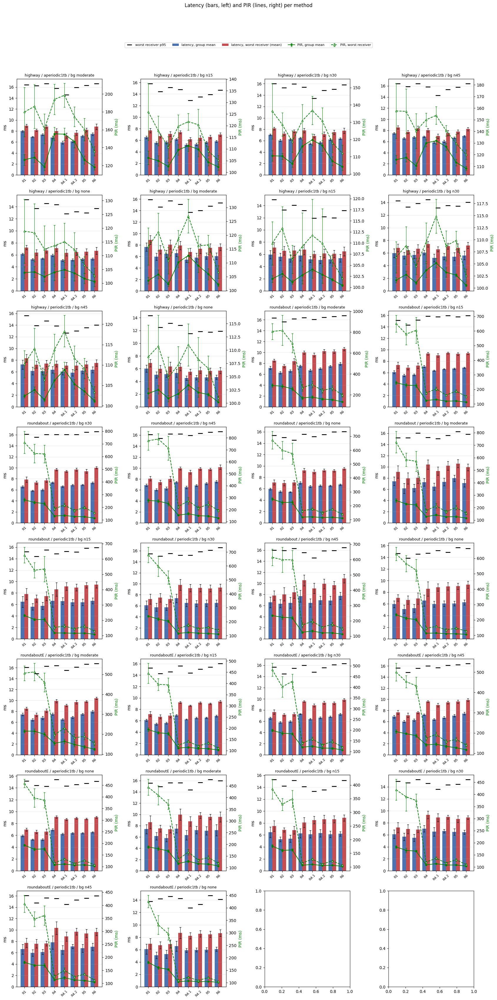

In [38]:
cell_grid(lat_panel, 'Latency (bars, left) and PIR (lines, right) per method')

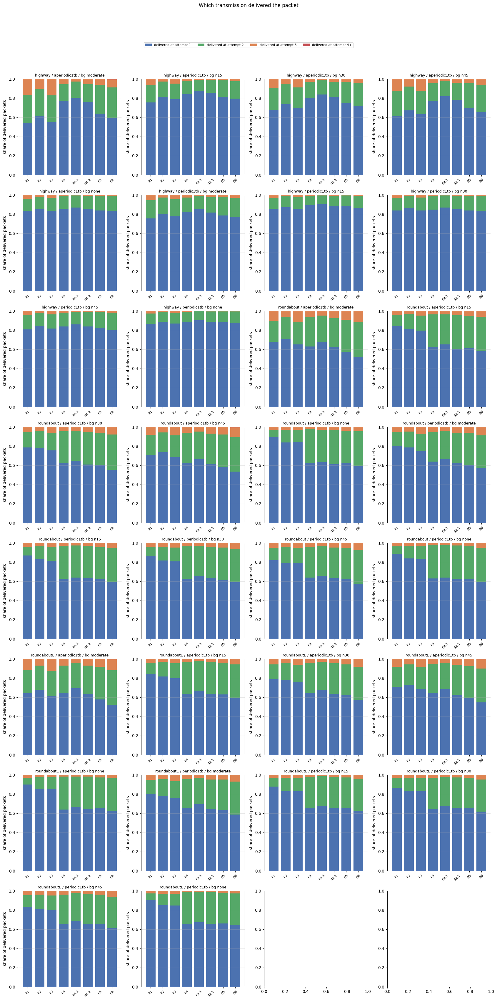

In [39]:
cell_grid(att_panel, 'Which transmission delivered the packet')

In [40]:
ref = {'R1': 'R1', 'R2': 'R1', 'R3': 'R1', 'R4': 'R4', 'R4.1': 'R4', 'R4.2': 'R4', 'R5': 'R4', 'R6': 'R4'}
L = LAT[LAT.arm.isin(ORDER)].set_index(CELLS + ['arm'])
G = []
for (sc, tr, bg, arm), r in L.iterrows():
    b = L.loc[(sc, tr, bg, ref[arm])]
    G.append(dict(scenario=sc, traffic=tr, bg=bg, arm=arm, vs=ref[arm],
        d_lat_group_ms=r.lat_group - b.lat_group, d_lat_worst_ms=r.lat_worst - b.lat_worst,
        d_lat_p95_worst_ms=r.lat_p95_worst - b.lat_p95_worst,
        d_pir_group_ms=r.pir_group - b.pir_group, d_pir_worst_ms=r.pir_worst - b.pir_worst))
LG = pd.DataFrame(G)
display(LAT[LAT.arm.isin(ORDER)].round(2))
LG.round(2)

,scenario,traffic,bg,arm,lat_group,lat_p95_group,lat_worst,lat_p95_worst,late_share,pir_group,pir_worst,pir_p95_worst,pir_max
0,highway,aperiodic1tb,moderate,R1,7.98,15.76,8.98,16.41,0.0,126.35,179.80,437.73,944.95
2,highway,aperiodic1tb,moderate,R2,6.94,14.81,8.15,16.24,0.0,129.08,186.05,467.32,992.25
3,highway,aperiodic1tb,moderate,R3,7.35,15.81,8.79,16.65,0.0,118.48,160.91,391.88,797.25
4,highway,aperiodic1tb,moderate,R4,6.83,14.11,7.98,15.77,0.0,155.33,193.84,484.68,1032.25
5,highway,aperiodic1tb,moderate,R4.1,5.91,12.46,7.15,14.62,0.0,155.01,198.56,505.74,1266.30
...,...,...,...,...,...,...,...,...,...,...,...,...,...
410,roundaboutE,periodic1tb,none,R4,6.55,13.22,8.69,14.24,0.0,103.98,109.86,181.70,601.10
411,roundaboutE,periodic1tb,none,R4.1,5.88,11.60,8.24,12.76,0.0,106.95,121.55,240.78,959.90
413,roundaboutE,periodic1tb,none,R4.2,5.96,11.70,8.55,13.30,0.0,104.04,109.04,176.13,571.40
416,roundaboutE,periodic1tb,none,R5,5.99,11.85,8.48,14.74,0.0,104.89,120.51,240.18,1072.15


,scenario,traffic,bg,arm,vs,d_lat_group_ms,d_lat_worst_ms,d_lat_p95_worst_ms,d_pir_group_ms,d_pir_worst_ms
0,highway,aperiodic1tb,moderate,R1,R1,0.00,0.00,0.00,0.00,0.00
1,highway,aperiodic1tb,moderate,R2,R1,-1.04,-0.84,-0.16,2.74,6.26
2,highway,aperiodic1tb,moderate,R3,R1,-0.62,-0.19,0.24,-7.87,-18.89
3,highway,aperiodic1tb,moderate,R4,R4,0.00,0.00,0.00,0.00,0.00
4,highway,aperiodic1tb,moderate,R4.1,R4,-0.92,-0.82,-1.15,-0.32,4.72
...,...,...,...,...,...,...,...,...,...,...
235,roundaboutE,periodic1tb,none,R4,R4,0.00,0.00,0.00,0.00,0.00
236,roundaboutE,periodic1tb,none,R4.1,R4,-0.67,-0.45,-1.48,2.98,11.69
237,roundaboutE,periodic1tb,none,R4.2,R4,-0.59,-0.13,-0.93,0.06,-0.82
238,roundaboutE,periodic1tb,none,R5,R4,-0.57,-0.20,0.50,0.91,10.65


## Latency CDF with the PRR as ceiling, and age of information
* **Latency CDF**: P(a sent packet reaches a member within t ms), over **all** sent (packet, member) pairs, so dropped packets
  count (they never arrive): the curve saturates at the PRR, and its value at the PDB (dotted line) is the PRR within the PDB.
  Second figure: the worst receiver only (lowest PRR member).
* **Age of information (AoI)**: at each instant, the age of the freshest packet a member holds (now minus its send time).
  It grows linearly between receptions and drops at each fresher reception; a loss lets it keep growing, a late
  retransmission adds its latency. Time-averaged per member; *group* = mean over members, *worst* = largest; peak AoI =
  mean of the age just before each update. Lower is better; it combines latency and loss in one number.

In [41]:

# Latency CDF with the PRR as ceiling, and age of information (AoI), per member, KPI window.
#  CDF: F(t) = P(a sent (packet, member) is received within t ms) over ALL sent pairs: lost packets never
#       arrive, so the curve saturates at the PRR; F(PDB) is the PRR within the PDB.
#  AoI: at time tau a member's age = tau - (send time of the freshest packet it has received); an older
#       packet arriving late does not lower it, a loss lets it grow until the next reception.
#       Time-average over [first reception, end of the KPI window]; peak AoI = age just before each update.
TGRID = np.linspace(0, 100, 401)
cdf_rows, aoi_rows = [], []
for armdir in sorted(glob.glob(os.path.join(OUT, '*', ''))):
    arm = os.path.basename(armdir.rstrip('/'))
    if arm not in ORDER + KUO:
        continue
    for p in sorted(glob.glob(armdir + '*_pkt.csv*')):
        tag = os.path.basename(p).split('_pkt.csv')[0]
        cc = cell_of(tag)
        pre = os.path.join(armdir, tag)
        k1 = rd(pre + '_run.csv').iloc[0].kpi_end
        d = rd(pre + '_pkt.csv')
        dl = np.where(d.rx == 1, d.delay_ms, np.inf)
        cdf_all = (dl[:, None] <= TGRID[None, :]).mean(axis=0)
        worst_m = d.groupby('member').rx.mean().idxmin()
        w = d.member == worst_m
        cdf_w = (dl[w.values][:, None] <= TGRID[None, :]).mean(axis=0)
        cdf_rows.append(dict(arm=arm, **cc, cdf=cdf_all, cdf_worst=cdf_w))
        per = []
        for m, g in d[d.rx == 1].groupby('member'):
            t_rx = (g.t_tx + g.delay_ms / 1e3).values
            o = np.argsort(t_rx); t_rx, t_gen = t_rx[o], g.t_tx.values[o]
            fresh = np.maximum.accumulate(t_gen)
            ts = np.append(t_rx, k1)
            area = peak = 0.0; peaks = []
            for i in range(len(t_rx)):
                a0, a1 = t_rx[i] - fresh[i], ts[i + 1] - fresh[i]
                area += (a0 + a1) / 2 * (ts[i + 1] - t_rx[i])
                peaks.append(a1)
            span = k1 - t_rx[0]
            per.append(dict(member=m, aoi=1e3 * area / span if span > 0 else np.nan, peak=1e3 * np.mean(peaks)))
        per = pd.DataFrame(per)
        aoi_rows.append(dict(arm=arm, **cc, aoi_group=per.aoi.mean(), aoi_worst=per.aoi.max(),
                             paoi_group=per.peak.mean(), paoi_worst=per.peak.max()))
CDF = pd.DataFrame(cdf_rows); AOIT = pd.DataFrame(aoi_rows).groupby(CELLS + ['arm']).mean(numeric_only=True).drop(columns='seed').reset_index()
AOICI = mean_ci(pd.DataFrame(aoi_rows), ['aoi_group', 'aoi_worst'], CELLS + ['arm'])

def cdf_panel(which):
    def f(ax, sc, tr, bg):
        d = CDF[(CDF.scenario == sc) & (CDF.traffic == tr) & (CDF.bg == bg)]
        for arm in ORDER:
            g = d[d.arm == arm]
            if len(g):
                col, ls = STYLE[arm]
                st = np.stack(g[which].values)
                mu = st.mean(axis=0)
                ax.plot(TGRID, mu, ls, color=col, lw=1.6, label=LABEL[arm])
                if len(st) > 1:   # 95 % CI over seeds
                    h = stats.t.ppf(0.975, len(st) - 1) * st.std(axis=0, ddof=1) / np.sqrt(len(st))
                    ax.fill_between(TGRID, mu - h, mu + h, color=col, alpha=.12, lw=0)
        ax.axvline(PDB_MS[tr], color='k', lw=.8, ls=':')
        ax.set_xlabel('latency t (ms)'); ax.set_ylabel('P(received within t)'); ax.set_ylim(0, 1.01)
    return f

def aoi_panel(ax, sc, tr, bg):
    d = pick(AOIT, sc, tr, bg); x = np.arange(len(d)); w = .38
    c = pick(AOICI, sc, tr, bg)
    ek = dict(capsize=2, error_kw=dict(lw=.8))
    ax.bar(x - w / 2, d.aoi_group, w, yerr=c.aoi_group_ci, color='#4c72b0', label='AoI, group mean', **ek)
    ax.bar(x + w / 2, d.aoi_worst, w, yerr=c.aoi_worst_ci, color='#c44e52', label='AoI, worst receiver', **ek)
    ax.plot(x + w / 2, d.paoi_worst, 'k_', ms=12, mew=2, label='peak AoI, worst receiver')
    ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_ylabel('ms')


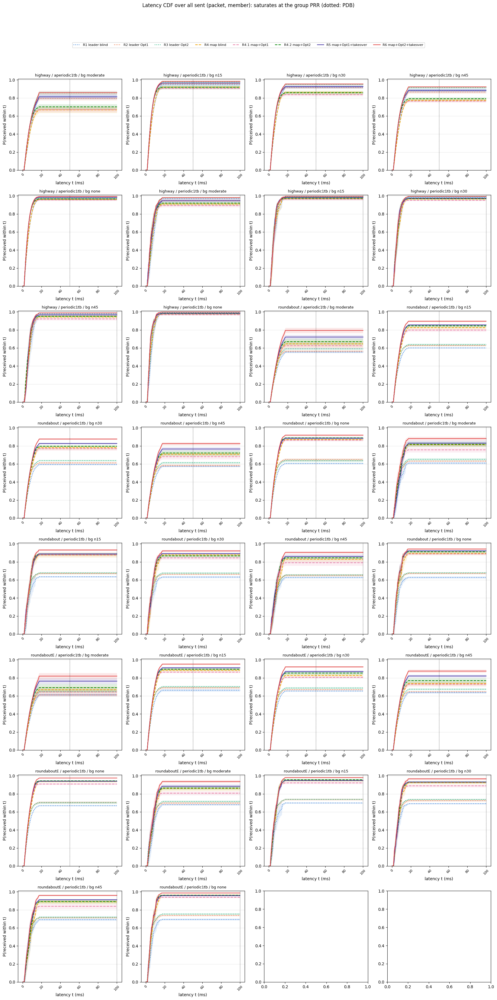

In [42]:
cell_grid(cdf_panel('cdf'), 'Latency CDF over all sent (packet, member): saturates at the group PRR (dotted: PDB)')

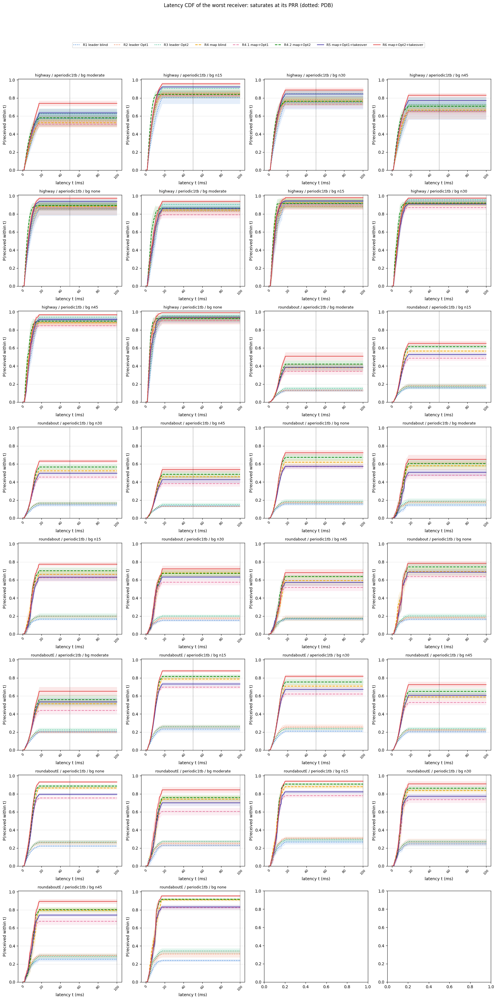

In [43]:
cell_grid(cdf_panel('cdf_worst'), 'Latency CDF of the worst receiver: saturates at its PRR (dotted: PDB)')

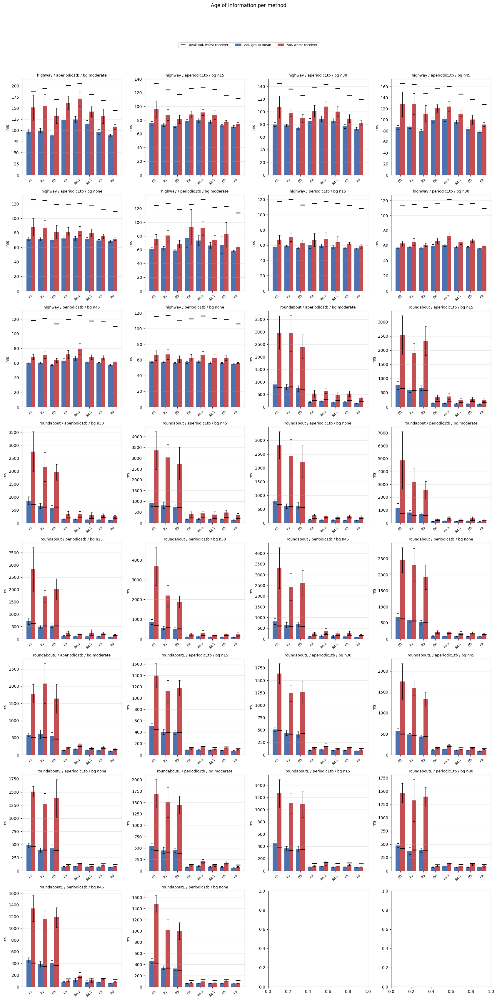

In [44]:
cell_grid(aoi_panel, 'Age of information per method')

In [45]:
AOIT[AOIT.arm.isin(ORDER)].round(1)

,scenario,traffic,bg,arm,aoi_group,aoi_worst,paoi_group,paoi_worst
0,highway,aperiodic1tb,moderate,R1,97.5,151.1,134.3,188.4
1,highway,aperiodic1tb,moderate,R2,99.3,155.2,136.0,193.9
2,highway,aperiodic1tb,moderate,R3,88.6,132.9,125.8,169.4
3,highway,aperiodic1tb,moderate,R4,123.5,162.3,162.0,201.2
4,highway,aperiodic1tb,moderate,R4.1,124.3,171.2,160.9,205.1
...,...,...,...,...,...,...,...,...
380,roundaboutE,periodic1tb,none,R4,61.9,73.2,110.5,118.4
381,roundaboutE,periodic1tb,none,R4.1,66.7,96.5,112.8,129.5
383,roundaboutE,periodic1tb,none,R4.2,61.1,70.8,109.9,117.5
386,roundaboutE,periodic1tb,none,R5,65.0,102.0,110.8,128.8


## Disconnection Time (DT)

**Source.** A. Rolich, M. Yildiz, A. Baiocchi, "Safety-Critical Delays in Vehicular Networks Toward 6G: A Novel Metric for Disconnection Time Assessment", *IEEE Communications Letters*, vol. 30, pp. 1860–1864, 2026, doi:10.1109/LCOMM.2026.3685872 (Sec. III).

**Definition (paper).** The disconnection time $D_{ij}(t)$ of receiver $j$ with respect to transmitter $i$ is the time elapsing between two consecutive successful receptions at $j$ from $i$, *provided that at least one message transmitted by $i$ has been lost to $j$ in between*.

Let $I_1, \dots, I_m$ be the inter-reception intervals at $j$ of messages from $i$ ($I_h = a_h - a_{h-1}$, $a_h$ = reception times), and $I_{j_1}, \dots, I_{j_k}$ ($k \le m$) the subset of intervals that contain at least one lost message. Then

$$\overline{PIR}_{ij} = \frac{1}{m}\sum_{h=1}^{m} I_h, \qquad \overline{DT}_{ij} = \frac{1}{k}\sum_{\ell=1}^{k} I_{j_\ell}.$$

PIR averages over **all** gaps, so at high PRR it is dominated by gaps of one generation period and hides the long outages; DT keeps **only the gaps with a loss**, so it measures how long a receiver stays blind once it loses the flow (e.g. persistent collisions under SPS). The paper reports the mean DT vs transmitter–receiver distance and argues for tail statistics as safety indicators (a 1 s outage every 100 s at PRR 0.99 is invisible in PRR and PIR).

**In this study.** Transmitter $i$ = the platoon leader, receiver $j$ = each member 1..8; a "message" is a leader packet (`_pkt.csv`: one row per packet × member, `rx`, `t_tx`, `delay_ms`). Our leader traffic is one TB per packet (`periodic1tb`: 100 ms; `aperiodic1tb`: 50 ms + Exp(50 ms)), HARQ / helper retransmissions are attempts of the same message, so a message counts as lost only if no copy delivered it. 

**Adaptation agreed for this study (HARQ / helper retransmissions).** The paper assumes broadcast with one transmission per message; here a message can be sent several times (leader retransmissions, helper copies, takeovers). To keep DT a property of the *message flow* and not of the transmissions:

1. **One reception per message.** A message is "received" by member $j$ once, at its **first successful decode** (any copy: initial, retransmission, helper copy). Later copies of an already decoded message are duplicates: they are neither receptions nor gaps (`_pkt.csv` already holds one row per (message, member) with the first-decode delay; the code asserts it). A failed transmission is not a loss as long as some copy of the message is decoded.
2. **Lost message.** Two loss rules, both reported: (a) *never received* (no copy decoded, as PRR); (b) *not received within the PDB* (100 ms periodic, 50 ms aperiodic; a late message counts as lost, as PRR-within-PDB).
3. **Intervals in message order.** Received messages are taken in generation (sequence) order; the interval between two consecutive received messages $p < q$ is a DT sample iff at least one message between them is lost. All intervals (lost or not) give the PIR for comparison.
4. **Two time bases**, both reported: *reception* $DT = a_q - a_p$ ($a$ = first-decode time; the paper's definition, includes the extra delay of a late HARQ / helper recovery) and *generation* $DT = g_q - g_p$ (the loss pattern alone). A reception-based interval can be ≤ 0 if $q$ was delivered before $p$ (out of order); such samples are counted and reported.
5. **KPI window edges.** Losses before the first or after the last reception of a member in the KPI window are censored outages: dropped from DT (paper: a sample needs two receptions), their number is reported.
6. **Statistics** per run, then mean ± 95 % CI over the 10 seeds: mean DT (per member, averaged over members), worst-member mean DT, p95 and max over all DT samples of the run, P(DT > 300 ms) and P(DT > 1 s) over the DT samples, and the mean DT vs leader–member distance (the paper's Fig. 4).


In [46]:
# Disconnection Time (DT) per (run, member), 4 variants: time base {rx, gen} x loss rule {lost, pdb}.
# See the definition cell above; one reception per message = first decode (no duplicates).
DT_ARMS = [a for a in ORDER + ['R1_bsc'] if os.path.isdir(os.path.join(OUT, a))]   # plotted
DT_ALL = DT_ARMS + KUO                                                             # computed
DT_VARIANTS = [(tb, lr) for tb in ('rx', 'gen') for lr in ('lost', 'pdb')]
THETAS_MS = (300.0, 1000.0)

def dt_samples(g, pdb_ms, base, rule):
    """g: one member's messages in the KPI window (one row per seq). Returns (DT samples ms, PIR samples ms,
    censored outages, out-of-order intervals)."""
    g = g.sort_values('seq')
    ok = (g.rx.values == 1) if rule == 'lost' else ((g.rx.values == 1) & (g.delay_ms.values <= pdb_ms))
    pos = np.flatnonzero(ok)
    if len(pos) < 2:
        return np.array([]), np.array([]), int((~ok).any()), 0
    t = g.t_tx.values * 1e3 + (g.delay_ms.values if base == 'rx' else 0.0)
    gaps = np.diff(t[pos])
    lost_between = np.diff(pos) > 1
    censored = int(pos[0] > 0) + int(pos[-1] < len(ok) - 1)
    return gaps[lost_between], gaps, censored, int((gaps <= 0).sum())

dt_rows, dtm_rows = [], []
for arm in DT_ALL:
    for p in sorted(glob.glob(os.path.join(OUT, arm, '*_pkt.csv*'))):
        tag = os.path.basename(p).split('_pkt.csv')[0]
        cc = cell_of(tag)
        d = rd(os.path.join(OUT, arm, tag) + '_pkt.csv')[['seq', 't_tx', 'member', 'rx', 'delay_ms', 'dist_m']]
        assert not d.duplicated(['seq', 'member']).any(), f'duplicate (message, member) rows in {arm}/{tag}'
        pdb = PDB_MS[cc['traffic']]
        for base, rule in DT_VARIANTS:
            pooled, per_m, cens, ooo = [], [], 0, 0
            for m, g in d.groupby('member'):
                s, pir, c, o = dt_samples(g, pdb, base, rule)
                cens += c; ooo += o
                pooled.append(s)
                per_m.append(dict(member=m, dt_mean=s.mean() if len(s) else np.nan, n_dt=len(s),
                                  pir_mean=pir.mean() if len(pir) else np.nan, dist=g.dist_m.mean()))
                dtm_rows.append(dict(arm=arm, **cc, base=base, rule=rule, member=m, dist=g.dist_m.mean(),
                                     dt_mean=per_m[-1]['dt_mean'], n_dt=len(s)))
            s = np.concatenate(pooled) if pooled else np.array([])
            pm = pd.DataFrame(per_m)
            dt_rows.append(dict(arm=arm, **cc, base=base, rule=rule,
                                dt_mean=pm.dt_mean.mean(),            # members without any outage are skipped
                                dt_worst=pm.dt_mean.max(),
                                dt_p95=np.percentile(s, 95) if len(s) else np.nan,
                                dt_max=s.max() if len(s) else np.nan,
                                p_dt_300=(s > THETAS_MS[0]).mean() if len(s) else np.nan,
                                p_dt_1000=(s > THETAS_MS[1]).mean() if len(s) else np.nan,
                                n_dt=len(s), pir_mean=pm.pir_mean.mean(), censored=cens, out_of_order=ooo))
DT = pd.DataFrame(dt_rows); DTM = pd.DataFrame(dtm_rows)
DT_COLS = ['dt_mean', 'dt_worst', 'dt_p95', 'dt_max', 'p_dt_300', 'p_dt_1000', 'pir_mean']
DTCI = mean_ci(DT, DT_COLS + ['n_dt', 'censored', 'out_of_order'], CELLS + ['base', 'rule', 'arm'])
print(f"{len(DT) // len(DT_VARIANTS)} runs x {len(DT_VARIANTS)} variants; arms {DT_ARMS}")
print('out-of-order reception intervals (rx base):', int(DT[DT.base == 'rx'].out_of_order.sum()),
      '| censored outages dropped:', int(DT[(DT.base == 'rx') & (DT.rule == 'lost')].censored.sum()))


4200 runs x 4 variants; arms ['R1', 'R2', 'R3', 'R4', 'R4.1', 'R4.2', 'R5', 'R6', 'R1_bsc']
out-of-order reception intervals (rx base): 0 | censored outages dropped: 2987


In [47]:
# DT summary (mean over seeds; +- = 95 % CI). Default view: reception time base, "never received" loss rule
# (the paper's definition); the other three variants are in DTCI (filter base / rule).
def dt_table(base='rx', rule='lost', cols=('dt_mean', 'dt_worst', 'dt_p95', 'dt_max', 'p_dt_300', 'p_dt_1000', 'pir_mean')):
    t = DTCI[(DTCI.base == base) & (DTCI.rule == rule) & DTCI.arm.isin(DT_ARMS)].copy()
    t['arm'] = pd.Categorical(t.arm, DT_ARMS)
    out = t.sort_values(CELLS + ['arm'])[CELLS + ['arm']].copy()
    for c in cols:
        prec = 3 if c.startswith('p_') else 0
        out[c] = t[c].round(prec).astype(str) + ' ±' + t[c + '_ci'].round(prec).astype(str)
    return out.set_index(CELLS + ['arm'])

display(dt_table('rx', 'lost'))
# the four variants side by side for the mean DT (ms)
v = DTCI.pivot_table(index=CELLS + ['arm'], columns=['base', 'rule'], values='dt_mean').round(0)
v = v.reindex([i for i in v.index if i[3] in DT_ARMS]); v


dt_mean       dt_worst         dt_p95         dt_max      p_dt_300     p_dt_1000    pir_mean
scenario    traffic      bg       arm                                                                                                     
highway     aperiodic1tb moderate R1      224.0 ±11.0    279.0 ±28.0    453.0 ±24.0   945.0 ±180.0  0.222 ±0.033  0.001 ±0.001  126.0 ±6.0
                                  R2       232.0 ±8.0    285.0 ±29.0    468.0 ±37.0   992.0 ±123.0  0.222 ±0.021  0.001 ±0.001  129.0 ±5.0
                                  R3       214.0 ±6.0    265.0 ±19.0    428.0 ±12.0   797.0 ±153.0  0.192 ±0.017    0.0 ±0.001  118.0 ±4.0
                                  R4       254.0 ±7.0    295.0 ±16.0    503.0 ±25.0  1032.0 ±166.0  0.279 ±0.028  0.001 ±0.001  155.0 ±7.0
                                  R4.1     254.0 ±7.0    297.0 ±16.0    525.0 ±28.0  1266.0 ±207.0  0.284 ±0.033  0.002 ±0.001  155.0 ±7.0
...                                               ...            ...            ...            ...           ...           ...         ...
roundaboutE periodic1tb  none     R4.1    240.0 ±11.0    307.0 ±26.0    468.0 ±79.0   960.0 ±123.0  0.155 ±0.044  0.003 ±0.003  107.0 ±1.0
                                  R4.2     226.0 ±9.0    267.0 ±17.0    345.0 ±42.0   571.0 ±111.0  0.085 ±0.046      0.0 ±0.0  104.0 ±1.0
                                  R5      248.0 ±14.0    325.0 ±24.0   546.0 ±102.0  1072.0 ±231.0  0.211 ±0.039  0.011 ±0.007  105.0 ±1.0
                                  R6       219.0 ±9.0    257.0 ±20.0    321.0 ±36.0    460.0 ±68.0  0.118 ±0.051      0.0 ±0.0  101.0 ±0.0
                                  R1_bsc  644.0 ±52.0  1229.0 ±167.0  2657.0 ±374.0  6002.0 ±492.0  0.525 ±0.039   0.17 ±0.027  163.0 ±4.0

[270 rows x 7 columns]

base                                        gen            rx       
rule                                       lost    pdb   lost    pdb
scenario    traffic      bg       arm                               
highway     aperiodic1tb moderate R1      224.0  224.0  224.0  224.0
                                  R1_bsc  218.0  218.0  218.0  218.0
                                  R2      232.0  232.0  232.0  232.0
                                  R3      214.0  214.0  214.0  214.0
                                  R4      254.0  254.0  254.0  254.0
...                                         ...    ...    ...    ...
roundaboutE periodic1tb  none     R4      230.0  230.0  229.0  229.0
                                  R4.1    240.0  240.0  240.0  240.0
                                  R4.2    226.0  226.0  226.0  226.0
                                  R5      248.0  248.0  248.0  248.0
                                  R6      219.0  219.0  219.0  219.0

[270 rows x 4 columns]

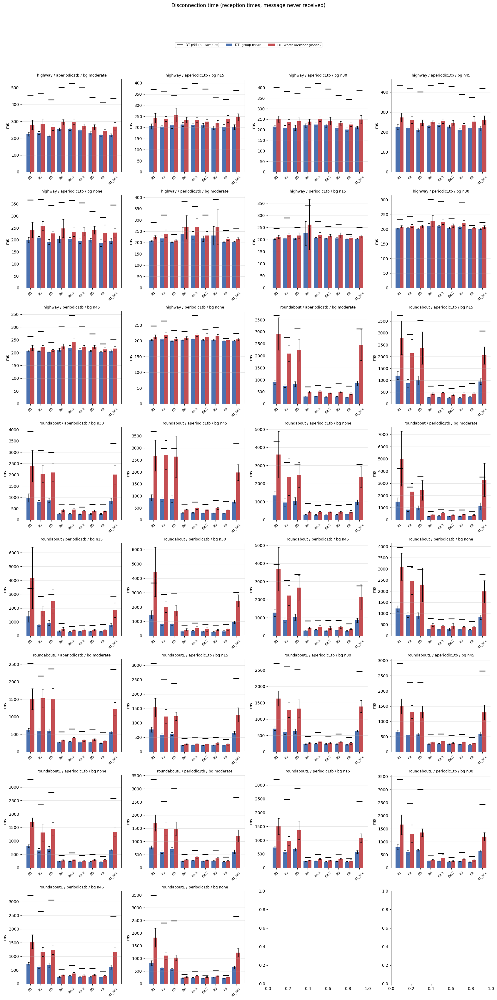

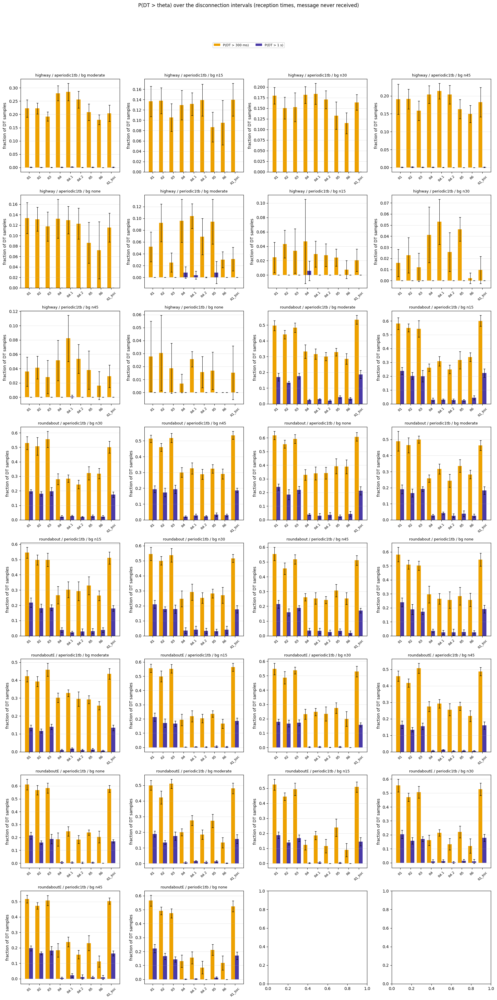

In [48]:
# DT bars per cell: group mean, worst member (95 % CI over seeds), p95 marker; second figure: P(DT > theta)
def dt_panel(base, rule):
    def f(ax, sc, tr, bg):
        d = DTCI[(DTCI.base == base) & (DTCI.rule == rule) & (DTCI.scenario == sc) & (DTCI.traffic == tr) &
                 (DTCI.bg == bg)].set_index('arm').reindex([a for a in DT_ARMS if a in set(DTCI.arm)])
        x = np.arange(len(d)); w = .38; ek = dict(capsize=2, error_kw=dict(lw=.8))
        ax.bar(x - w / 2, d.dt_mean, w, yerr=d.dt_mean_ci, color='#4c72b0', label='DT, group mean', **ek)
        ax.bar(x + w / 2, d.dt_worst, w, yerr=d.dt_worst_ci, color='#c44e52', label='DT, worst member (mean)', **ek)
        ax.plot(x, d.dt_p95, 'k_', ms=14, mew=2, label='DT p95 (all samples)')
        ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_ylabel('ms')
    return f

def pdt_panel(base, rule):
    def f(ax, sc, tr, bg):
        d = DTCI[(DTCI.base == base) & (DTCI.rule == rule) & (DTCI.scenario == sc) & (DTCI.traffic == tr) &
                 (DTCI.bg == bg)].set_index('arm').reindex([a for a in DT_ARMS if a in set(DTCI.arm)])
        x = np.arange(len(d)); w = .38; ek = dict(capsize=2, error_kw=dict(lw=.8))
        ax.bar(x - w / 2, d.p_dt_300, w, yerr=d.p_dt_300_ci, color='#eda100', label='P(DT > 300 ms)', **ek)
        ax.bar(x + w / 2, d.p_dt_1000, w, yerr=d.p_dt_1000_ci, color='#4a3aa7', label='P(DT > 1 s)', **ek)
        ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_ylabel('fraction of DT samples')
    return f

cell_grid(dt_panel('rx', 'lost'), 'Disconnection time (reception times, message never received)')
cell_grid(pdt_panel('rx', 'lost'), 'P(DT > theta) over the disconnection intervals (reception times, message never received)')


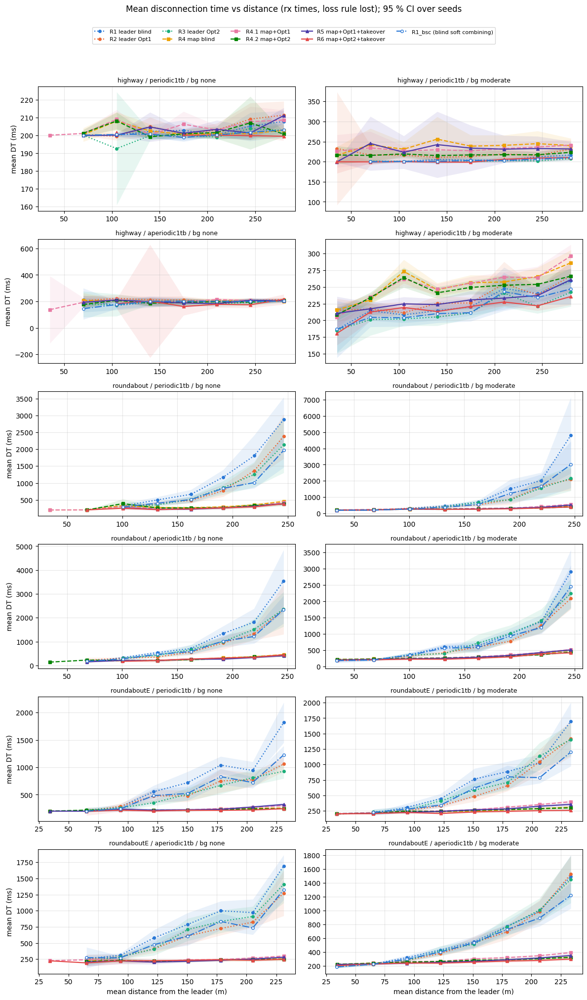

In [49]:
# Mean DT vs leader-member distance (the paper's Fig. 4): per member, mean over seeds (95 % CI shaded)
def dt_dist_plot(base='rx', rule='lost', arms=None):
    arms = arms or DT_ARMS
    scen = [s for s in ['highway', 'roundabout', 'roundaboutE'] if s in set(DTM.scenario)]
    trafs, bgs = ['periodic1tb', 'aperiodic1tb'], ['none', 'moderate']
    D = DTM[(DTM.base == base) & (DTM.rule == rule)]
    fig, axes = plt.subplots(len(scen) * len(trafs), len(bgs), figsize=(12, 3.3 * len(scen) * len(trafs)), squeeze=False)
    for i, (sc, tr) in enumerate([(s, t) for s in scen for t in trafs]):
        for j, bg in enumerate(bgs):
            ax = axes[i, j]
            d = D[(D.scenario == sc) & (D.traffic == tr) & (D.bg == bg)]
            for arm in arms:
                g = mean_ci(d[d.arm == arm], ['dist', 'dt_mean'], 'member').sort_values('dist')
                if len(g):
                    col, ls = STYLE[arm.replace('_bsc', '')]
                    bsc = arm.endswith('_bsc')
                    ax.plot(g.dist, g.dt_mean, '-.' if bsc else ls, color=col, lw=1.6, marker=MARK[ls], ms=4,
                            mfc='white' if bsc else col, label=LABEL.get(arm, arm + ' (blind soft combining)'))
                    ax.fill_between(g.dist, g.dt_mean - g.dt_mean_ci, g.dt_mean + g.dt_mean_ci, color=col, alpha=.10, lw=0)
            ax.set_title(f'{sc} / {tr} / bg {bg}', fontsize=9); ax.grid(alpha=.3)
            if j == 0: ax.set_ylabel('mean DT (ms)')
            if i == len(scen) * len(trafs) - 1: ax.set_xlabel('mean distance from the leader (m)')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=min(len(h), 5), fontsize=8, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f'Mean disconnection time vs distance ({base} times, loss rule {rule}); 95 % CI over seeds', y=1.02)
    fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

dt_dist_plot('rx', 'lost')


## HARQ-IR (soft-combining) gain
Not available on the v3 data: the `_noIR` arms were not re-run after the stale-NDI fix (pre-fix result, deleted: `pre_ndi/STUDY_RESULTS_remote_full.ipynb`). The fix does not touch the combining of copies that follow a corrupt copy of the same TB, and `combining_evidence.py` confirms the SINR shift is unchanged on v2 (R3 3.27 -> 3.28 dB, R4.2 1.82 -> 1.71 dB).

## Helper takeover (R5 / R6): helper NACKs, leader fallback, PRR gain
* `helper_nack`: NACKs of the named helper received by the leader (each lets it retake a handed slot; `helper_reclaim`).
* `fallback_check`: handed slots in which a relay was expected; `fallback_heard`: the leader decoded the helper's SCI there;
  `fallback_tx`: nothing heard, the leader retransmitted in the next handed slot; `fallback_no_slot`: nothing heard, no slot left.
* `recovered_*`: member-packets first delivered by those leader retransmissions (PRR points attributable to each mechanism).
* `d_prr_vs_no_takeover`: R5 - R4.1 and R6 - R4.2 (whole takeover effect, including retransmission timing).

,scenario,traffic,bg,arm,helper_nack,helper_reclaim,fallback_check,fallback_heard,fallback_tx,fallback_no_slot,recovered_nack,recovered_fallback,d_prr_vs_no_takeover,d_prr_worst_vs_no_takeover
0,highway,aperiodic1tb,moderate,R5,148.6,126.4,337.6,241.3,83.2,13.1,0.0783,0.0508,0.1423,0.1249
1,highway,aperiodic1tb,moderate,R6,154.9,126.4,409.8,279.2,107.7,22.9,0.0782,0.0639,0.1565,0.1606
2,highway,aperiodic1tb,n15,R5,70.5,66.7,296.1,271.0,23.4,1.7,0.0402,0.0164,0.0591,0.0953
3,highway,aperiodic1tb,n15,R6,64.3,60.3,343.8,314.0,27.8,2.0,0.0367,0.0195,0.0651,0.1175
4,highway,aperiodic1tb,n30,R5,95.2,86.0,335.0,286.4,44.2,4.4,0.0554,0.0261,0.0904,0.1144
5,highway,aperiodic1tb,n30,R6,96.9,85.9,387.4,324.9,54.5,8.0,0.0534,0.0354,0.0962,0.1246
6,highway,aperiodic1tb,n45,R5,111.9,100.2,338.0,273.9,57.4,6.7,0.0699,0.0352,0.1198,0.1215
7,highway,aperiodic1tb,n45,R6,108.9,94.0,406.6,320.1,73.8,12.7,0.0659,0.0448,0.1311,0.1220
8,highway,aperiodic1tb,none,R5,50.7,49.1,319.7,313.2,6.1,0.4,0.0224,0.0024,0.0282,0.0657
9,highway,aperiodic1tb,none,R6,47.4,45.2,357.0,348.1,8.1,0.8,0.0192,0.0034,0.0278,0.0795


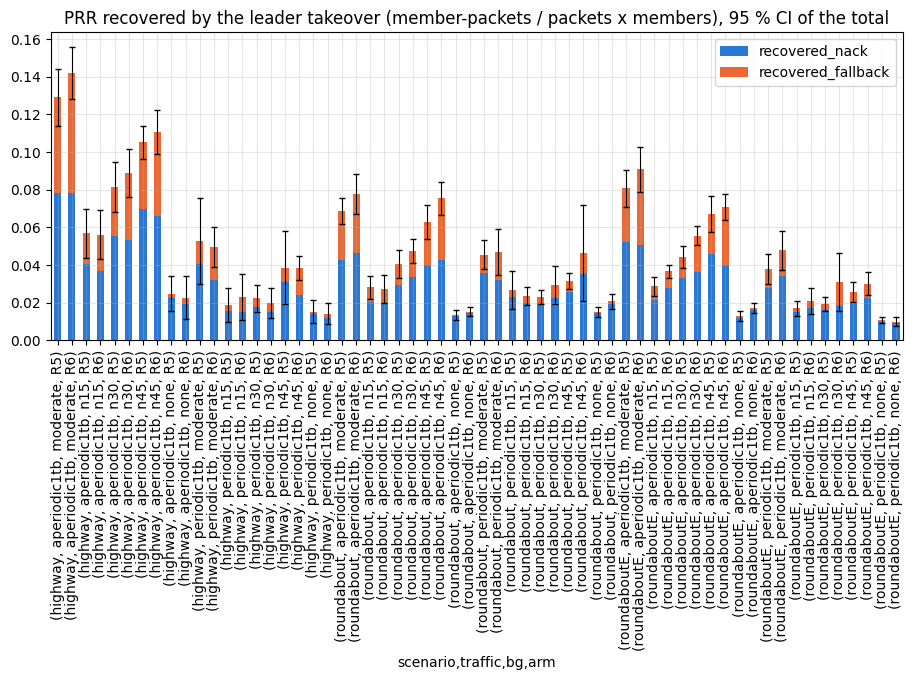

In [50]:

tk = R[R.arm.isin(['R5', 'R6'])].groupby(CELLS + ['arm']).agg(
        helper_nack=('helper_nack', 'mean'), helper_reclaim=('helper_reclaim', 'mean'),
        fallback_check=('fallback_check', 'mean'), fallback_heard=('fallback_heard', 'mean'),
        fallback_tx=('fallback_tx', 'mean'), fallback_no_slot=('fallback_no_slot', 'mean'),
        recovered_nack=('recovered_nack', 'mean'), recovered_fallback=('recovered_fallback', 'mean')).reset_index()
base = {'R5': 'R4.1', 'R6': 'R4.2'}
a = agg.set_index(CELLS + ['arm'])
tk['d_prr_vs_no_takeover'] = [a.prr.get((r.scenario, r.traffic, r.bg, r.arm), np.nan) -
                              a.prr.get((r.scenario, r.traffic, r.bg, base[r.arm]), np.nan) for r in tk.itertuples()]
tk['d_prr_worst_vs_no_takeover'] = [a.prr_worst.get((r.scenario, r.traffic, r.bg, r.arm), np.nan) -
                                    a.prr_worst.get((r.scenario, r.traffic, r.bg, base[r.arm]), np.nan) for r in tk.itertuples()]
display(tk.round(4))
x = tk.set_index(CELLS + ['arm'])[['recovered_nack', 'recovered_fallback']]
ax = x.plot.bar(stacked=True, figsize=(11, 4), color=['#2a78d6', '#eb6834'],
                title='PRR recovered by the leader takeover (member-packets / packets x members), 95 % CI of the total')
tc = mean_ci(R[R.arm.isin(['R5', 'R6'])].assign(t=lambda r: r.recovered_nack + r.recovered_fallback), ['t'],
             CELLS + ['arm']).set_index(CELLS + ['arm']).reindex(x.index)
ax.errorbar(np.arange(len(x)), x.sum(axis=1).values, yerr=tc.t_ci.values, fmt='none', ecolor='k', elinewidth=.8, capsize=2)
plt.grid(alpha=.3); plt.show()


## Map vs Kuo, same arm (paired by seed)

For each helper arm, cell and seed: the map run minus the Kuo run (same command except `--helperSelect`, so the
same traces and random streams up to the first different helper choice). Mean over the 10 seeds and 95 % Student-t
CI; *better* / *worse* only when the CI excludes 0. Higher is better for the PRR metrics; lower is better for the
cost, latency, AoI and DT metrics.

| metric | meaning |
|---|---|
| `prr`, `prr_worst`, `prr_pdb` | group PRR, worst member, group PRR within the PDB |
| `ss_kB`, `tx_per_pkt` | transmitted subchannel-slots per kB of payload, transmitted subchannel-slots per packet |
| `lat_group`, `lat_worst` | mean latency (ms), group and worst receiver |
| `aoi_group`, `aoi_worst` | mean age of information (ms), group and worst receiver |
| `dt_mean`, `dt_worst` | mean disconnection time (ms; reception times, message never received), group and worst member |

In [51]:

HARMS = ['R4', 'R4.1', 'R4.2', 'R5', 'R6']
KUO = [a + '_kuo' for a in HARMS]
BG_N = {'none': 0, 'n15': 15, 'n30': 30, 'n45': 45, 'moderate': 60}
SCENS, TRAFS = ['highway', 'roundabout', 'roundaboutE'], ['periodic1tb', 'aperiodic1tb']
HIGHER = {'prr': True, 'prr_worst': True, 'prr_pdb': True, 'ss_kB': False, 'tx_per_pkt': False,
          'lat_group': False, 'lat_worst': False, 'aoi_group': False, 'aoi_worst': False,
          'dt_mean': False, 'dt_worst': False}
K = CELLS + ['seed', 'arm']
runs_m = R[['arm'] + CELLS + ['seed', 'prr', 'prr_worst', 'prr_pdb', 'ss_kB', 'tx_per_pkt']]
lat_m = pd.DataFrame(lat_rows)[['arm'] + CELLS + ['seed', 'lat_group', 'lat_worst']]
aoi_m = pd.DataFrame(aoi_rows)[['arm'] + CELLS + ['seed', 'aoi_group', 'aoi_worst']]
dt_m = DT[(DT.base == 'rx') & (DT.rule == 'lost')][['arm'] + CELLS + ['seed', 'dt_mean', 'dt_worst']]
PER_RUN = runs_m.merge(lat_m, on=['arm'] + CELLS + ['seed'], how='left') \
               .merge(aoi_m, on=['arm'] + CELLS + ['seed'], how='left') \
               .merge(dt_m, on=['arm'] + CELLS + ['seed'], how='left')
mp = PER_RUN[PER_RUN.arm.isin(HARMS)].set_index(K).sort_index()
kq = PER_RUN[PER_RUN.arm.isin(KUO)].assign(arm=lambda x: x.arm.str[:-4]).set_index(K).sort_index()
assert len(mp) == len(kq) == len(mp.index.intersection(kq.index)), 'map and Kuo runs do not pair'
DIFF = (mp - kq.loc[mp.index]).reset_index()
rows = []
for (sc, tr, bg, arm), g in DIFF.groupby(CELLS + ['arm']):
    for m, hi in HIGHER.items():
        x = g[m].dropna()
        d, ci = x.mean(), ci95(x)
        better = (d - ci > 0) if hi else (d + ci < 0)
        worse = (d + ci < 0) if hi else (d - ci > 0)
        rows.append(dict(scenario=sc, traffic=tr, bg=bg, nbg=BG_N[bg], arm=arm, metric=m, d=d, ci=ci, n=len(x),
                         kuo=kq.loc[(sc, tr, bg), m].xs(arm, level='arm').mean(),
                         map=mp.loc[(sc, tr, bg), m].xs(arm, level='arm').mean(),
                         verdict='better' if better else ('worse' if worse else 'tie')))
CMP = pd.DataFrame(rows)
CMP.to_csv('out/study_v3_map_cmp.csv', index=False)   # one row per (cell, arm, metric)
print(f'{len(DIFF)} paired (map, Kuo) runs, {DIFF.groupby(CELLS + ["arm"]).ngroups} (cell, arm) groups')


1500 paired (map, Kuo) runs, 150 (cell, arm) groups


### Verdict counts
Cells (3 routes x 2 traffic types x 5 loads = 30 per arm) where map is better / tied / worse than Kuo for the same
arm, per metric, split into the curve (both roundabout routes, 20 cells) and the highway (10 cells).

In [52]:

C2 = CMP.assign(zone=np.where(CMP.scenario == 'highway', 'highway', 'curve'))
V = C2.groupby(['metric', 'arm', 'zone']).verdict.value_counts().unstack(fill_value=0).reindex(
    columns=['better', 'tie', 'worse'], fill_value=0)
V = V.join(C2.groupby(['metric', 'arm', 'zone']).d.agg(['mean', 'min', 'max']))
with pd.option_context('display.max_rows', 500):
    display(V.reindex(list(HIGHER), level=0).round(4))


better  tie  worse      mean        min       max
metric     arm  zone                                                      
prr        R4   curve        20    0      0    0.0758     0.0297    0.1311
                highway       0   10      0    0.0042    -0.0067    0.0179
           R4.1 curve        17    3      0    0.0564     0.0150    0.1265
                highway       0    9      1   -0.0018    -0.0139    0.0061
           R4.2 curve        20    0      0    0.0681     0.0232    0.1359
                highway       0   10      0   -0.0003    -0.0043    0.0067
           R5   curve        20    0      0    0.0661     0.0386    0.1118
                highway       0   10      0   -0.0005    -0.0036    0.0022
           R6   curve        20    0      0    0.0818     0.0455    0.1202
                highway       0   10      0    0.0001    -0.0025    0.0019
prr_worst  R4   curve        20    0      0    0.2311     0.1343    0.2959
                highway       0   10      0    0.0011    -0.0235    0.0231
           R4.1 curve        20    0      0    0.1623     0.0946    0.2520
                highway       0    9      1   -0.0076    -0.0223    0.0068
           R4.2 curve        20    0      0    0.2278     0.1576    0.3166
                highway       0   10      0   -0.0020    -0.0118    0.0097
           R5   curve        20    0      0    0.1680     0.1324    0.2061
                highway       0    9      1   -0.0032    -0.0123    0.0052
           R6   curve        20    0      0    0.2459     0.1555    0.3145
                highway       0   10      0    0.0001    -0.0095    0.0101
prr_pdb    R4   curve        20    0      0    0.0758     0.0297    0.1311
                highway       0   10      0    0.0042    -0.0067    0.0179
           R4.1 curve        17    3      0    0.0564     0.0150    0.1265
                highway       0    9      1   -0.0018    -0.0139    0.0061
           R4.2 curve        20    0      0    0.0681     0.0232    0.1359
                highway       0   10      0   -0.0003    -0.0043    0.0067
           R5   curve        20    0      0    0.0661     0.0386    0.1118
                highway       0   10      0   -0.0005    -0.0036    0.0022
           R6   curve        20    0      0    0.0818     0.0455    0.1202
                highway       0   10      0    0.0001    -0.0025    0.0019
ss_kB      R4   curve        10    7      3   -0.3067    -1.1059    0.7324
                highway       0    8      2    0.0848    -0.0679    0.3233
           R4.1 curve        15    4      1   -0.9976    -2.1586    0.4194
                highway       0   10      0   -0.0440    -0.2545    0.0409
           R4.2 curve        19    1      0   -1.6907    -3.0953   -0.1300
                highway       0   10      0   -0.0352    -0.1802    0.0299
           R5   curve        18    2      0   -0.9474    -1.9287    0.0549
                highway       0   10      0    0.0856    -0.0255    0.3005
           R6   curve        20    0      0   -1.3703    -2.4810   -0.3874
                highway       0    9      1   -0.0345    -0.4622    0.2383
tx_per_pkt R4   curve        10    7      3   -0.0655    -0.4865    0.5373
                highway       0    8      2    0.0375    -0.0169    0.1177
           R4.1 curve        15    4      1   -0.2799    -0.5374    0.3095
                highway       0   10      0   -0.0100    -0.0634    0.0313
           R4.2 curve        19    1      0   -0.5828    -0.7709   -0.0939
                highway       0   10      0   -0.0176    -0.0465    0.0074
           R5   curve        18    2      0   -0.3453    -0.6630    0.0396
                highway       0   10      0    0.0271    -0.0177    0.0748
           R6   curve        20    0      0   -0.5224    -0.8817   -0.2820
                highway       0    9      1   -0.0065    -0.1151    0.0849
lat_group  R4   curve         0    7     13    0.2321    -0.1891    0.5407
                highway       0   10      0   -0.0

### Paired difference vs load
One panel per route and traffic type, one line per helper arm: mean of (map - Kuo) over seeds, shaded = 95 % CI,
x = background vehicles. Above zero is better for the PRR rows and worse for the others.

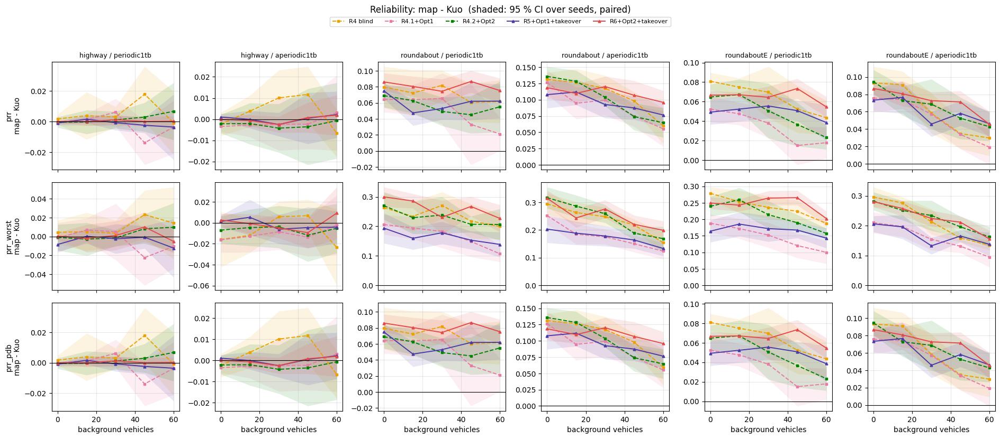

In [53]:

def cmp_plot(metrics, title):
    fig, axes = plt.subplots(len(metrics), 6, figsize=(19, 2.7 * len(metrics)), sharex=True, squeeze=False)
    for i, m in enumerate(metrics):
        for j, (sc, tr) in enumerate([(s, t) for s in SCENS for t in TRAFS]):
            ax = axes[i, j]
            x = CMP[(CMP.metric == m) & (CMP.scenario == sc) & (CMP.traffic == tr)]
            for arm in HARMS:
                g = x[x.arm == arm].sort_values('nbg')
                col, ls = STYLE[arm]
                ax.plot(g.nbg, g.d, ls, color=col, marker=MARK[ls], ms=3.5, lw=1.4, label=LABEL[arm].replace(' map', ''))
                ax.fill_between(g.nbg, g.d - g.ci, g.d + g.ci, color=col, alpha=.12, lw=0)
            ax.axhline(0, color='k', lw=.8)
            ax.grid(alpha=.3)
            if i == 0: ax.set_title(f'{sc} / {tr}', fontsize=9)
            if j == 0: ax.set_ylabel(f'{m}\nmap - Kuo')
            if i == len(metrics) - 1: ax.set_xlabel('background vehicles')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(title + '  (shaded: 95 % CI over seeds, paired)', y=1.02)
    fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

cmp_plot(['prr', 'prr_worst', 'prr_pdb'], 'Reliability: map - Kuo')


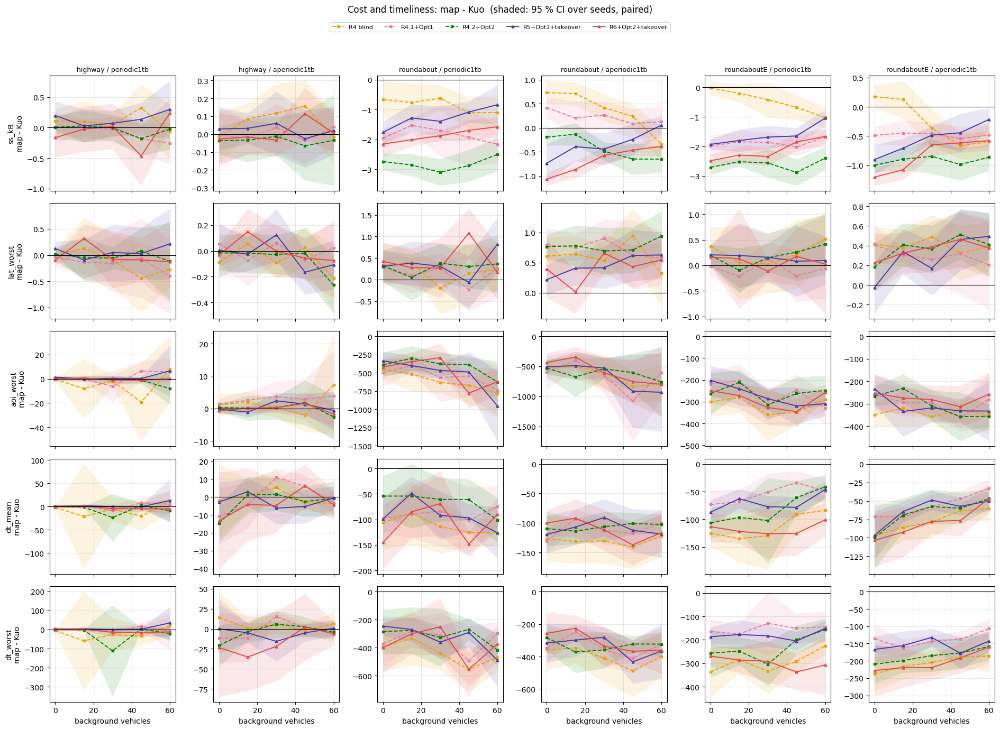

In [54]:
cmp_plot(['ss_kB', 'lat_worst', 'aoi_worst', 'dt_mean', 'dt_worst'], 'Cost and timeliness: map - Kuo')

### Levels: Opt 2 (R3) against the helper arms with each selection
Group and worst-member PRR vs load, mean over seeds (95 % CI shaded). Solid = map, dashed = Kuo, dotted = R3
(leader-only Option 2, the strongest leader scheme).

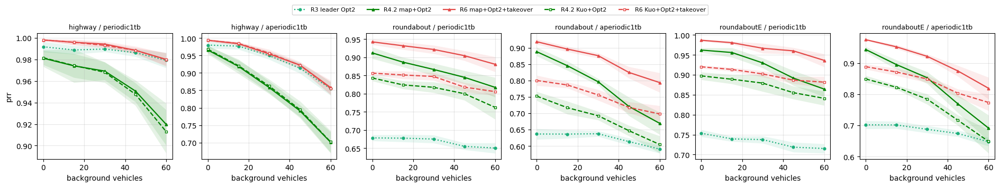

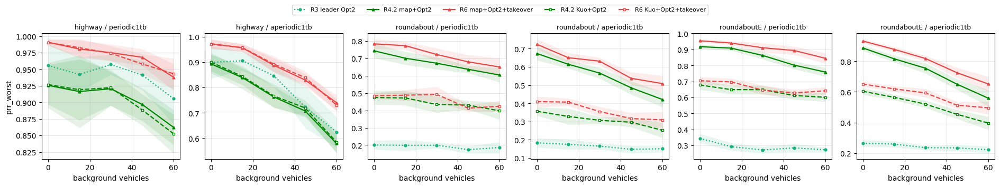

R6 map - R3  R6 Kuo - R3  R4.2 map - R3  R4.2 Kuo - R3
scenario    traffic      bg       nbg                                                        
highway     aperiodic1tb moderate 60         0.003        0.001         -0.153         -0.153
                         n15      15         0.007        0.008         -0.058         -0.056
                         n30      30         0.004        0.007         -0.092         -0.088
                         n45      45         0.009        0.008         -0.122         -0.119
                         none     0          0.014        0.014         -0.014         -0.012
            periodic1tb  moderate 60         0.001        0.001         -0.059         -0.066
                         n15      15         0.007        0.007         -0.015         -0.014
                         n30      30         0.005        0.003         -0.020         -0.022
                         n45      45         0.002        0.002         -0.036         -0.039
                         none     0          0.006        0.006         -0.011         -0.010
roundabout  aperiodic1tb moderate 60         0.203        0.108          0.079          0.014
                         n15      15         0.260        0.150          0.209          0.081
                         n30      30         0.239        0.119          0.159          0.055
                         n45      45         0.211        0.105          0.107          0.033
                         none     0          0.282        0.164          0.252          0.116
            periodic1tb  moderate 60         0.230        0.155          0.167          0.112
                         n15      15         0.254        0.174          0.209          0.147
                         n30      30         0.246        0.172          0.191          0.142
                         n45      45         0.249        0.163          0.190          0.145
                         none     0          0.264        0.178          0.234          0.165
roundaboutE aperiodic1tb moderate 60         0.171        0.126          0.044          0.001
                         n15      15         0.251        0.170          0.194          0.121
                         n30      30         0.234        0.161          0.166          0.097
                         n45      45         0.201        0.130          0.095          0.043
                         none     0          0.273        0.187          0.242          0.147
            periodic1tb  moderate 60         0.221        0.167          0.149          0.126
                         n15      15         0.241        0.174          0.217          0.150
                         n30      30         0.229        0.165          0.192          0.142
                         n45      45         0.242        0.168          0.173          0.137
                         none     0          0.233        0.167          0.209          0.144

In [55]:

LV = mean_ci(PER_RUN.assign(nbg=PER_RUN.bg.map(BG_N)), ['prr', 'prr_worst'], ['arm'] + CELLS + ['nbg'])
def level_plot(metric, arms=('R4.2', 'R6')):
    fig, axes = plt.subplots(1, 6, figsize=(19, 3.3), sharex=True, squeeze=False)
    for j, (sc, tr) in enumerate([(s, t) for s in SCENS for t in TRAFS]):
        ax = axes[0, j]
        x = LV[(LV.scenario == sc) & (LV.traffic == tr)]
        lines = [('R3', 'R3', ':', 'R3 leader Opt2')]
        lines += [(a, a, '-', LABEL[a]) for a in arms] + [(a + '_kuo', a, '--', LABEL[a].replace('map', 'Kuo')) for a in arms]
        for key, base, ls, lab in lines:
            g = x[x.arm == key].sort_values('nbg')
            col = STYLE[base][0]
            ax.plot(g.nbg, g[metric], ls, color=col, lw=1.6, marker='o' if ls == ':' else ('^' if ls == '-' else 's'),
                    ms=3.5, mfc='white' if ls == '--' else col, label=lab)
            ax.fill_between(g.nbg, g[metric] - g[metric + '_ci'], g[metric] + g[metric + '_ci'], color=col, alpha=.1, lw=0)
        ax.set_title(f'{sc} / {tr}', fontsize=9); ax.grid(alpha=.3); ax.set_xlabel('background vehicles')
    axes[0, 0].set_ylabel(metric)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, 1.08))
    fig.tight_layout(); plt.show()

level_plot('prr'); level_plot('prr_worst')
gain = LV.pivot_table(index=CELLS + ['nbg'], columns='arm', values='prr')
pd.DataFrame({'R6 map - R3': gain['R6'] - gain['R3'], 'R6 Kuo - R3': gain['R6_kuo'] - gain['R3'],
              'R4.2 map - R3': gain['R4.2'] - gain['R3'], 'R4.2 Kuo - R3': gain['R4.2_kuo'] - gain['R3']}).round(3)


### PRR vs distance, map vs Kuo
R6 (cooperative protocol) and R4.2 (helper + Option 2, no takeover), map (solid) against Kuo (dashed), with R3
(dotted) as reference; one point per member, shaded = 95 % CI over seeds.

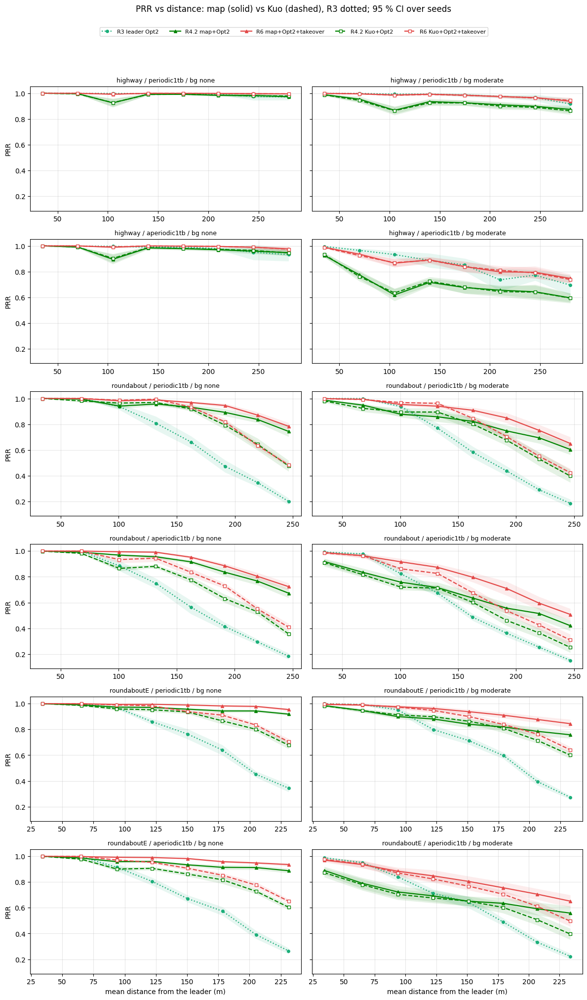

In [56]:

def dist_cmp(arms=('R4.2', 'R6')):
    trafs, bgs = TRAFS, ['none', 'moderate']
    fig, axes = plt.subplots(len(SCENS) * len(trafs), len(bgs), figsize=(12, 3.3 * len(SCENS) * len(trafs)),
                             sharey=True, squeeze=False)
    lines = [('R3', 'R3', ':', 'R3 leader Opt2')] + [(a, a, '-', LABEL[a]) for a in arms] + \
            [(a + '_kuo', a, '--', LABEL[a].replace('map', 'Kuo')) for a in arms]
    for i, (sc, tr) in enumerate([(s, t) for s in SCENS for t in trafs]):
        for j, bg in enumerate(bgs):
            ax = axes[i, j]
            d = M[(M.scenario == sc) & (M.traffic == tr) & (M.bg == bg)]
            for key, base, ls, lab in lines:
                g = mean_ci(d[d.arm == key], ['dist', 'prr'], 'member').sort_values('dist')
                col = STYLE[base][0]
                ax.plot(g.dist, g.prr, ls, color=col, lw=1.6, marker='o' if ls == ':' else ('^' if ls == '-' else 's'),
                        ms=4, mfc='white' if ls == '--' else col, label=lab)
                ax.fill_between(g.dist, g.prr - g.prr_ci, g.prr + g.prr_ci, color=col, alpha=.1, lw=0)
            ax.set_title(f'{sc} / {tr} / bg {bg}', fontsize=9); ax.grid(alpha=.3)
            if j == 0: ax.set_ylabel('PRR')
            if i == len(SCENS) * len(trafs) - 1: ax.set_xlabel('mean distance from the leader (m)')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle('PRR vs distance: map (solid) vs Kuo (dashed), R3 dotted; 95 % CI over seeds', y=1.02)
    fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()
dist_cmp()


### Which helper each selection picks (R6)
Share of the TBs in which each member is named helper (`helper_share_m1..m8`), helper changes per second, and the
share of named TBs whose helper failed the leader's first copy (`helper_corrupt_tx / helper_named_tx`); mean over
seeds, R6, 0 and 60 background vehicles.

In [57]:

hrows = []
for key in ('R6', 'R6_kuo'):
    for p in sorted(glob.glob(os.path.join(OUT, key, '*_run.csv*'))):
        tag = os.path.basename(p).split('_run.csv')[0]
        r = rd(os.path.join(OUT, key, tag) + '_run.csv').iloc[0]
        hrows.append(dict(sel='map' if key == 'R6' else 'kuo', **cell_of(tag),
                          **{f'm{i}': r[f'helper_share_m{i}'] for i in range(1, 9)},
                          changes_per_s=r.helper_changes_per_s,
                          missed_copy1=r.helper_corrupt_tx / r.helper_named_tx if r.helper_named_tx else np.nan))
HS = pd.DataFrame(hrows)
HS = HS[HS.bg.isin(['none', 'moderate'])].groupby(CELLS + ['sel']).mean(numeric_only=True).drop(columns='seed')
(100 * HS[[f'm{i}' for i in range(1, 9)]]).round(0).join(HS[['changes_per_s', 'missed_copy1']].round(3))


m1    m2     m3    m4    m5    m6   m7   m8  changes_per_s  missed_copy1
scenario    traffic      bg       sel                                                                            
highway     aperiodic1tb moderate kuo   0.0  16.0   84.0   0.0   0.0   0.0  0.0  0.0          2.624         0.295
                                  map   0.0   0.0  100.0   0.0   0.0   0.0  0.0  0.0          0.000         0.297
                         none     kuo   0.0  16.0   84.0   0.0   0.0   0.0  0.0  0.0          2.757         0.092
                                  map   0.0   0.0  100.0   0.0   0.0   0.0  0.0  0.0          0.000         0.095
            periodic1tb  moderate kuo   0.0   3.0   97.0   0.0   0.0   0.0  0.0  0.0          0.266         0.111
                                  map   0.0   0.0  100.0   0.0   0.0   0.0  0.0  0.0          0.000         0.105
                         none     kuo   0.0   3.0   97.0   0.0   0.0   0.0  0.0  0.0          0.272         0.064
                                  map   0.0   0.0  100.0   0.0   0.0   0.0  0.0  0.0          0.000         0.062
roundabout  aperiodic1tb moderate kuo   0.0  68.0   32.0   0.0   0.0   0.0  0.0  0.0          1.797         0.288
                                  map   0.0  39.0   24.0  10.0  13.0  15.0  0.0  0.0          1.066         0.272
                         none     kuo   0.0  69.0   31.0   0.0   0.0   0.0  0.0  0.0          1.690         0.217
                                  map   0.0  41.0   21.0  10.0  13.0  15.0  0.0  0.0          1.122         0.094
            periodic1tb  moderate kuo   0.0  89.0   11.0   0.0   0.0   0.0  0.0  0.0          0.079         0.136
                                  map   0.0  36.0   26.0  10.0  12.0  15.0  0.0  0.0          0.493         0.207
                         none     kuo   0.0  88.0   12.0   0.0   0.0   0.0  0.0  0.0          0.087         0.077
                                  map   0.0  37.0   25.0  10.0  13.0  15.0  0.0  0.0          0.535         0.126
roundaboutE aperiodic1tb moderate kuo  14.0  42.0   33.0  11.0   0.0   0.0  0.0  0.0          2.104         0.268
                                  map   2.0  21.0   24.0  15.0  27.0  11.0  0.0  0.0          1.165         0.288
                         none     kuo  14.0  42.0   32.0  11.0   0.0   0.0  0.0  0.0          1.938         0.136
                                  map   2.0  21.0   23.0  14.0  29.0  11.0  0.0  0.0          1.149         0.102
            periodic1tb  moderate kuo  17.0  57.0   17.0   9.0   0.0   0.0  0.0  0.0          0.136         0.104
                                  map   2.0  22.0   23.0  15.0  29.0  10.0  0.0  0.0          0.765         0.171
                         none     kuo  18.0  56.0   17.0   9.0   0.0   0.0  0.0  0.0          0.171         0.066
                                  map   2.0  22.0   21.0  15.0  30.0  10.0  0.0  0.0          0.787         0.063

## Findings: map vs Kuo (2026-11-15, campaign v3, 1500 paired runs)

Counts below are cells out of 20 on the curve (both roundabout routes x 2 traffic types x 5 loads) and 10 on the
highway, per helper arm; *better* / *worse* = the paired 95 % CI excludes 0. Full table:
`out/study_v3_map_cmp.csv` and the verdict-count table above.

**1. On the curve, map is better than Kuo on every reliability, disconnection and freshness metric, for every
helper arm.**
- Group PRR: better in 20 / 20 cells for R4, R4.2, R5 and R6, in 17 / 20 for R4.1 (the rest ties). R6: +0.045 to
  +0.120 (+6 to +16 %).
- Worst-member PRR: better in 20 / 20 cells for every arm. R6: +0.16 to +0.32 (+31 to +78 %).
- PRR within the PDB moves exactly like the PRR: the PDB is never what limits delivery.
- Disconnection time: lower in 19-20 / 20 cells for every arm. R6: mean DT 47-148 ms shorter (-16 to -36 %),
  worst member 160-555 ms shorter (-35 to -59 %).
- Age of information: lower in 20 / 20 cells for every arm. R6: worst receiver 249-800 ms lower (-57 to -81 %).

**2. Map also costs less spectrum per delivered byte with Option 2, but its packets arrive slightly later.**
- Transmitted subchannel-slots per kB (`ss_kB`) on the curve: lower for R6 in 20 / 20 cells (-3 to -13 %) and for
  R4.2 in 19 / 20. Fewer leader retransmissions and takeovers are needed when the helper reaches the tail. For the
  blind helper (R4) it is mixed: 10 better, 7 ties, 3 worse.
- Mean latency on the curve: higher with map in 13 / 20 cells for R4, R4.2, R5 and R6, by up to 0.9 ms (R6: at most
  +13 %), and never significantly lower. More packets reach the tail through the helper's copy or a later copy instead of being
  lost, and a later copy takes longer. The disconnection time and AoI, which count the losses, improve far more.

**3. On the highway the two selections are the same.**
- Map names member 3 in every TB; Kuo names member 3 in 84 % of TBs with aperiodic traffic (member 2 in 16 %) and
  in 97 % with periodic traffic.
- Every metric ties in nearly every highway cell. Across the 11 metrics x 5 arms (550 highway verdicts) there are
  7 *better* and 17 *worse*, all small (group PRR within ±0.018). That is about what chance gives at 95 % (5 % of 550 is 28).

**4. The cooperative protocol keeps its lead, and map widens it on the curve.**
- R6 - R3 (leader-only Option 2), group PRR, curve: +0.17 to +0.28 with map, +0.11 to +0.19 with Kuo.
- Highway: R6 is at or slightly above R3 with either selection (+0.001 to +0.014).
- R4.2 (helper + Option 2, no takeover) with map is still below R3 on the loaded highway (-0.15 at 60 vehicles,
  aperiodic) and is below R6 in every cell (by at least 0.017).

**5. Why: map moves the helper back along the platoon.**
- Roundabout W: Kuo names member 2 in 68-89 % of TBs (else 3); map spreads the choice over members 2-6.
- Roundabout E: Kuo names members 1-4; map names members 2-6, most often member 5 (27-30 %).
- With periodic traffic the map helper misses the first copy more often (roundabout W: 0.13-0.21 against
  0.08-0.14), yet every reliability metric is far better: map gives up some of the leader -> helper link to get a
  clear helper -> tail link.

**Caveats**
- **Best case for a map choice:** the selector has exact CAM positions (`posErrM` = 0) and a perfect building map.
- **Timing of the choice:** the helper is chosen before the first copy; a choice after the first copy is not tested.
- **R4_bsc** (Kuo blind helper with soft combining) has no map run, so the DT section shows R1_bsc only.
